In [ ]:
#基础模型
# 开关: ties平滑处理重复值+two_sided双尾+门控+幂变换
# 固定使用optuna搜索FPR+trim_frac
import os
import numpy as np
import pandas as pd
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from dataclasses import dataclass, field
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    roc_auc_score,
)

# =========================
# 路径配置（按你给的）
# =========================
x = "normalization"
y = "binary"
z = "157"

benign_path = f'preprocess/dataset_0831/{x}/{y}/{z}/Benign_data.csv'
malicious_train_path = f'preprocess/dataset_0831/{x}/{y}/{z}/merged_filtered_data_train.csv'
malicious_test_path = f'preprocess/dataset_0831/{x}/{y}/{z}/merged_filtered_data_test.csv'

y = "test_camp"
malicious_train_path = f'preprocess/dataset_fanhua_new/{x}/{z}/{y}/merged_filtered_data_train.csv'
malicious_test_path = f'preprocess/dataset_fanhua_new/{x}/{z}/{y}/merged_filtered_data_test.csv'

# =========================
# 数据读写 & 特征抽取
# =========================
def load_csv(path: str) -> pd.DataFrame:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")
    return pd.read_csv(path)


def extract_xy(df: pd.DataFrame):
    if df.shape[1] < 4:
        raise ValueError(f"Expect >=4 columns, got {df.shape[1]}")
    label_col = df.columns[1]              # 第二列标签
    feature_cols = list(df.columns[3:])    # 第四列起特征
    y = pd.to_numeric(df[label_col], errors="coerce").fillna(0).astype(int).values
    X = df.loc[:, feature_cols].copy()
    for c in feature_cols:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    return X, y, feature_cols


# =========================
# 数学/评估工具
# =========================
def fbeta(p: float, r: float, beta: float) -> float:
    p = float(p); r = float(r); beta = float(beta)
    if p <= 0 or r <= 0:
        return 0.0
    b2 = beta * beta
    return (1 + b2) * p * r / (b2 * p + r)


def threshold_under_fpr_exact(benign_scores: np.ndarray, max_fpr: float) -> float:
    """
    选择阈值 thr，使得 mean(score>=thr) <= max_fpr，且尽量紧。
    特别处理 ties：必要时用 nextafter 上抬阈值。
    """
    s = np.asarray(benign_scores, dtype=float)
    n = len(s)
    max_fpr = float(max_fpr)
    if n == 0:
        raise ValueError("Empty benign_scores")

    if max_fpr <= 0:
        return float(np.nextafter(np.max(s), np.inf))

    allowed_fp = int(np.floor(max_fpr * n))
    if allowed_fp <= 0:
        return float(np.nextafter(np.max(s), np.inf))

    s_desc = np.sort(s)[::-1]
    thr = float(s_desc[allowed_fp - 1])
    while float(np.mean(s >= thr)) > max_fpr:
        thr = float(np.nextafter(thr, np.inf))
        if thr > float(np.max(s)):
            break
    return float(thr)


def evaluate_scores(z_b: np.ndarray, z_m: np.ndarray, thr: float, beta: float):
    z_b = np.asarray(z_b, dtype=float)
    z_m = np.asarray(z_m, dtype=float)
    y_true = np.concatenate([np.zeros_like(z_b, dtype=int), np.ones_like(z_m, dtype=int)])
    y_pred = np.concatenate([(z_b >= thr).astype(int), (z_m >= thr).astype(int)])

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    fpr = float(np.mean(z_b >= thr))
    try:
        auc = float(roc_auc_score(y_true, np.concatenate([z_b, z_m])))
    except Exception:
        auc = float("nan")
    return {
        "precision": float(p),
        "recall": float(r),
        "f1": float(f1),
        f"f{beta}": float(fbeta(p, r, beta=beta)),
        "fpr": fpr,
        "auc": auc,
    }


# =========================
# 模块开关配置（用于消融）
# =========================
@dataclass(frozen=True)
class ModuleSwitches:
    use_ties: bool = True              # ties-aware
    two_sided: bool = True             # two-sided p
    use_gate_t0: bool = True           # NEW: 是否启用门控 t0
    use_power_transform: bool = True   # NEW: 是否启用幂变换 gamma


# =========================
# Detector：经验分布 + p-value + 门控 + 幂变换 + 截断 + 聚合 + 标准化
# =========================
@dataclass
class TailDetector:
    t0: float = 0.0
    gamma: float = 1.5
    trim_frac: float = 0.0

    switches: ModuleSwitches = field(default_factory=ModuleSwitches)
    eps: float = 1e-12

    feature_cols_: list = field(default_factory=list)
    sorted_benign_: list = field(default_factory=list)
    medians_: np.ndarray | None = None
    loc_: float = 0.0
    scale_: float = 1.0

    def fit(self, X_benign: pd.DataFrame, feature_cols: list):
        self.feature_cols_ = feature_cols
        X = X_benign[feature_cols].values.astype(float)

        self.medians_ = np.nanmedian(X, axis=0)
        X = np.where(np.isnan(X), self.medians_, X)

        # 良性清洗（固定：trim_frac 始终可用，由 Optuna 决定）
        if self.trim_frac and self.trim_frac > 0:
            row_stat = np.nanmax(X, axis=1)
            thr = np.quantile(row_stat, 1.0 - float(self.trim_frac))
            X = X[row_stat <= thr]

        self.sorted_benign_ = [np.sort(X[:, j]) for j in range(X.shape[1])]

        # 这里你原本没有做 loc/scale 标准化（loc_=0, scale_=1）
        # 保持原逻辑不动
        _ = self._raw_scores_from_array(X)
        self.loc_, self.scale_ = 0.0, 1.0
        return self

    def _pvalues(self, sarr: np.ndarray, xcol: np.ndarray) -> np.ndarray:
        n = len(sarr)

        if self.switches.use_ties:
            lo = np.searchsorted(sarr, xcol, side="left")
            hi = np.searchsorted(sarr, xcol, side="right")
            eq = hi - lo

            left_mass = lo + 0.5 * eq
            right_mass = (n - hi) + 0.5 * eq

            p_low = (left_mass + 1.0) / (n + 2.0)
            p_up = (right_mass + 1.0) / (n + 2.0)

            p_low = np.clip(p_low, self.eps, 1.0)
            p_up = np.clip(p_up, self.eps, 1.0)

            if self.switches.two_sided:
                p = np.minimum(1.0, 2.0 * np.minimum(p_low, p_up))
            else:
                p = p_up
        else:
            idx = np.searchsorted(sarr, xcol, side="left")
            tail = (n - idx)
            p_up = (tail + 1.0) / (n + 2.0)
            p_up = np.clip(p_up, self.eps, 1.0)

            if self.switches.two_sided:
                p_low = (idx + 1.0) / (n + 2.0)
                p = np.minimum(1.0, 2.0 * np.minimum(p_low, p_up))
            else:
                p = p_up

        return np.clip(p, self.eps, 1.0)

    def _gate(self, u: np.ndarray) -> np.ndarray:
        # NEW：门控开关
        if self.switches.use_gate_t0:
            x = u - float(self.t0)
            return np.maximum(x, 0.0)
        else:
            return u

    def _raw_scores_from_array(self, X: np.ndarray) -> np.ndarray:
        n, d = X.shape
        raw = np.zeros(n, dtype=float)
        for j in range(d):
            sarr = self.sorted_benign_[j]
            p = self._pvalues(sarr, X[:, j])
            u = -np.log(p)

            a = self._gate(u)

            # NEW：幂变换开关
            if self.switches.use_power_transform and float(self.gamma) != 1.0:
                a = np.power(a, float(self.gamma))

            raw += a
        return raw

    def score_samples(self, X_any: pd.DataFrame) -> np.ndarray:
        X = X_any[self.feature_cols_].values.astype(float)
        X = np.where(np.isnan(X), self.medians_, X)
        raw = self._raw_scores_from_array(X)
        z = (raw - self.loc_) / (self.scale_ + self.eps)
        return z

# =========================
# Optuna 目标函数
# =========================
def build_objective(
    Xb_fit, Xb_cal, Xm_val, feat_cols,
    switches: ModuleSwitches,
    beta: float,
    fpr_low: float, fpr_high: float,
    fpr_penalty: float,
):
    def objective(trial: optuna.Trial) -> float:
        # 固定：始终由 Optuna 搜索 max_fpr_target
        max_fpr = trial.suggest_float("max_fpr_target", fpr_low, fpr_high, log=True)

        # detector 超参
        # 门控 t0：开关控制是否搜索/生效
        t0 = trial.suggest_float("t0", 0.0, 10.0) if switches.use_gate_t0 else 0.0

        # 幂变换 gamma：开关控制是否搜索/生效
        gamma = trial.suggest_float("gamma", 0.3, 7.0) if switches.use_power_transform else 1.0

        # 固定：trim_frac 始终由 Optuna 搜索
        trim_frac = trial.suggest_float("trim_frac", 0.001, 0.01)

        det = TailDetector(
            t0=t0,
            gamma=gamma,
            trim_frac=trim_frac,
            switches=switches
        ).fit(Xb_fit, feat_cols)

        z_b = det.score_samples(Xb_cal)
        z_m = det.score_samples(Xm_val)

        # 固定：阈值模块始终用 exact-FPR threshold
        thr = threshold_under_fpr_exact(z_b, max_fpr=max_fpr)

        metrics = evaluate_scores(z_b, z_m, thr, beta=beta)
        f1 = metrics["f1"]

        # 仍保留你原来的“让 Optuna 不要倾向过大 FPR”的惩罚
        penalty = fpr_penalty * np.log10(max_fpr / fpr_low)

        trial.set_user_attr("f1", float(f1))
        trial.set_user_attr("fpr_target", float(max_fpr))
        trial.set_user_attr("fpr_actual", float(metrics["fpr"]))
        trial.set_user_attr("precision", float(metrics["precision"]))
        trial.set_user_attr("recall", float(metrics["recall"]))
        trial.set_user_attr("auc", float(metrics["auc"]))

        return float(f1) - penalty

    return objective


# =========================
# 单个变体的训练 + 测试
# =========================
def run_variant(
    name: str,
    Xb_fit, Xb_cal, Xb_test,
    Xm_fit, Xm_val, Xm_test,
    feat_cols,
    switches: ModuleSwitches,
    n_trials: int,
    beta: float,
    fpr_low: float,
    fpr_high: float,
    fpr_penalty: float,
    seed: int,
):
    sampler = optuna.samplers.TPESampler(seed=seed)
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=max(10, n_trials // 6))
    
    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)

    obj = build_objective(
        Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xm_val=Xm_val, feat_cols=feat_cols,
        switches=switches, beta=beta,
        fpr_low=fpr_low, fpr_high=fpr_high, fpr_penalty=fpr_penalty,
    )
    study.optimize(obj, n_trials=n_trials, show_progress_bar=False)

    bp = study.best_params
    best_fpr = float(bp["max_fpr_target"])

    # 最终训练 detector
    det = TailDetector(
        t0=float(bp["t0"]) if switches.use_gate_t0 else 0.0,
        gamma=float(bp["gamma"]) if switches.use_power_transform else 1.0,
        trim_frac=float(bp["trim_frac"]),
        switches=switches,
    ).fit(Xb_fit, feat_cols)

    z_b_cal = det.score_samples(Xb_cal)
    z_m_fit = det.score_samples(Xm_fit)

    thr = threshold_under_fpr_exact(z_b_cal, max_fpr=best_fpr)
    calib_metrics = evaluate_scores(z_b_cal, z_m_fit, thr, beta=beta)

    # test
    z_b_test = det.score_samples(Xb_test)
    z_m_test = det.score_samples(Xm_test)
    test_metrics = evaluate_scores(z_b_test, z_m_test, thr, beta=beta)

    y_true = np.concatenate([np.zeros(len(z_b_test), dtype=int), np.ones(len(z_m_test), dtype=int)])
    y_pred = np.concatenate([(z_b_test >= thr).astype(int), (z_m_test >= thr).astype(int)])
    cm = confusion_matrix(y_true, y_pred)
    # print(f"best_t0: {float(bp['t0']) if switches.use_gate_t0 else 0.0}")
    # print(f"best_gamma: {float(bp['gamma']) if switches.use_power_transform else 1.0}")
    # print(f"best_trim_frac: {float(bp['trim_frac'])}")
    result = {
        "variant": name,
        "best_objective": float(study.best_value),
        "fpr_target": float(best_fpr),
        "threshold": float(thr),

        "calib_precision": calib_metrics["precision"],
        "calib_recall": calib_metrics["recall"],
        "calib_f1": calib_metrics["f1"],
        f"calib_f{beta}": calib_metrics[f"f{beta}"],
        "calib_fpr": calib_metrics["fpr"],
        "calib_auc": calib_metrics["auc"],

        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        f"test_f{beta}": test_metrics[f"f{beta}"],
        "test_fpr": test_metrics["fpr"],
        "test_auc": test_metrics["auc"],

        "test_TN": int(cm[0, 0]),
        "test_FP": int(cm[0, 1]),
        "test_FN": int(cm[1, 0]),
        "test_TP": int(cm[1, 1]),
    }
    return result


# =========================
# 消融实验主函数
# =========================
def run_ablation_suite(
    n_trials_full: int = 3,
    n_trials_ablation: int = 3,
    beta: float = 4.0,
    fpr_low: float = 1e-4,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
    save_csv: str = "ablation_results.csv",
    benign_path: str = benign_path,
    malicious_train_path: str = malicious_train_path,
    malicious_test_path: str = malicious_test_path,
):
    benign_df = load_csv(benign_path)
    mal_train_df = load_csv(malicious_train_path)
    mal_test_df = load_csv(malicious_test_path)

    Xb, yb, feat_cols_b = extract_xy(benign_df)
    Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
    Xm_te, ym_te, _ = extract_xy(mal_test_df)

    feat_cols = [c for c in feat_cols_b if c in Xm_tr.columns and c in Xm_te.columns]
    if len(feat_cols) == 0:
        raise ValueError("No common feature columns among datasets.")

    Xb = Xb[feat_cols]
    Xm_tr = Xm_tr[feat_cols]
    Xm_te = Xm_te[feat_cols]

    Xm_train_mal = Xm_tr[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr
    Xm_test_mal = Xm_te[ym_te == 1] if np.any(ym_te == 1) else Xm_te

    Xb_fit, Xb_tmp = train_test_split(Xb, test_size=0.30, random_state=seed, shuffle=True)
    Xb_cal, Xb_test = train_test_split(Xb_tmp, test_size=0.50, random_state=seed, shuffle=True)

    if len(Xm_train_mal) >= 20:
        Xm_fit, Xm_val = train_test_split(Xm_train_mal, test_size=0.30, random_state=seed, shuffle=True)
    else:
        Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal

    # print("==== Data Summary ====")
    # print(f"n_features: {len(feat_cols)}")
    # print(f"benign_fit={len(Xb_fit)}, benign_calib={len(Xb_cal)}, benign_test={len(Xb_test)}")
    # print(f"mal_fit={len(Xm_fit)}, mal_val={len(Xm_val)}, mal_test={len(Xm_test_mal)}")
    # print(f"FPR search range=[{fpr_low}, {fpr_high}] (Optuna always searches max_fpr_target)")
    # print(f"trim_frac is always searched by Optuna\n")

    variants = [
        ("FULL", ModuleSwitches(True, True, True, True), n_trials_full),
    ]

    results = []
    for name, sw, ntr in variants:
        print(f"=== Running Variant: {name} (trials={ntr}) ===")
        res = run_variant(
            name=name,
            Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xb_test=Xb_test,
            Xm_fit=Xm_fit, Xm_val=Xm_val, Xm_test=Xm_test_mal,
            feat_cols=feat_cols,
            switches=sw,
            n_trials=ntr,
            beta=beta,
            fpr_low=fpr_low,
            fpr_high=fpr_high,
            fpr_penalty=fpr_penalty,
            seed=seed,
        )
        results.append(res)

        print(f"  fpr_target={res['fpr_target']:.6g}, thr={res['threshold']:.6f}")
        print(f"  CALIB: P={res['calib_precision']:.4f} R={res['calib_recall']:.4f} F1={res['calib_f1']:.4f} FPR={res['calib_fpr']:.6f} AUC={res['calib_auc']:.4f}")
        print(f"  TEST : P={res['test_precision']:.4f} R={res['test_recall']:.4f} F1={res['test_f1']:.4f} FPR={res['test_fpr']:.6f} AUC={res['test_auc']:.4f}")
        print(f"  CM   : TN={res['test_TN']} FP={res['test_FP']} FN={res['test_FN']} TP={res['test_TP']}\n")

    df = pd.DataFrame(results)
    fbeta_col = f"test_f{beta}"
    df = df.sort_values(by=[fbeta_col, "test_f1", "test_recall"], ascending=False)

    print("==== Ablation Summary (sorted) ====")
    cols_show = [
        "variant", "fpr_target", "threshold",
        "test_precision", "test_recall", "test_f1", f"test_f{beta}", "test_fpr", "test_auc",
        "test_TN", "test_FP", "test_FN", "test_TP",
    ]
    print(df[cols_show].to_string(index=False))

    if save_csv:
        df.to_csv(save_csv, index=False)
        print(f"\nSaved to: {save_csv}")

    return df


if __name__ == "__main__":
    run_ablation_suite(
        n_trials_full=3,
        n_trials_ablation=3,
        beta=1,
        fpr_low=5e-5,
        fpr_high=2e-2,
        fpr_penalty=0.03,
        seed=42,
        save_csv="ablation_results.csv",
    )


=== Running Variant: FULL (trials=3) ===
  fpr_target=0.00183277, thr=5.651669
  CALIB: P=0.9664 R=0.9897 F1=0.9779 FPR=0.001580 AUC=0.9996
  TEST : P=0.9704 R=1.0000 F1=0.9850 FPR=0.001580 AUC=0.9992
  CM   : TN=6320 FP=10 FN=0 TP=328

==== Ablation Summary (sorted) ====
variant  fpr_target  threshold  test_precision  test_recall  test_f1  test_f1  test_fpr  test_auc  test_TN  test_FP  test_FN  test_TP
   FULL    0.001833   5.651669        0.970414          1.0 0.984985 0.984985   0.00158  0.999193     6320       10        0      328

Saved to: ablation_results.csv


In [ ]:
# =========================
# 多数据集评估函数 - 修正版
# =========================
def evaluate_multiple_datasets_with_proper_split(
    x_values: list = ["test_camp", "test_keytrap", "test_nxns", "test_camp+nxns"],
    n_trials_full: int = 2,
    beta: float = 4.0,
    fpr_low: float = 3e-5,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
):
    y = "normalization"
    z = "157"
    
    # 仅保留测试集混淆矩阵累加器（验证集指标在run_variant中已内部使用，无需外部累加）
    test_total_TN = 0
    test_total_FP = 0
    test_total_FN = 0
    test_total_TP = 0
    dataset_results = []
    
    for i, x in enumerate(x_values):
        print(f"\n--- [{i+1}/{len(x_values)}] Processing dataset: {x} ---")
        
        # 设置路径（保持不变）
        benign_path = f'preprocess/dataset_0831/{y}/binary/{z}/Benign_data.csv'
        malicious_train_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_train.csv'
        malicious_test_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_test.csv'
        
        try:
            # 加载数据（保持不变）
            benign_df = load_csv(benign_path)
            mal_train_df = load_csv(malicious_train_path)
            mal_test_df = load_csv(malicious_test_path)
            
            Xb, yb, feat_cols_b = extract_xy(benign_df)
            Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
            Xm_te, ym_te, _ = extract_xy(mal_test_df)
            
            # 特征对齐（保持不变）
            feat_cols = [c for c in feat_cols_b if c in Xm_tr.columns and c in Xm_te.columns]
            if len(feat_cols) == 0:
                raise ValueError("No common feature columns among datasets.")
            
            Xb = Xb[feat_cols]
            Xm_tr = Xm_tr[feat_cols]
            Xm_te = Xm_te[feat_cols]
            
            # 仅保留恶意样本（保持不变）
            Xm_train_mal = Xm_tr[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr
            Xm_test_mal = Xm_te[ym_te == 1] if np.any(ym_te == 1) else Xm_te

            # ======== CRITICAL FIX: 按照代码A的逻辑重新划分数据 ========
            # 1. 良性数据划分: 70%训练 → [50%校准, 50%测试] = (70%, 15%, 15%)
            Xb_fit, Xb_tmp = train_test_split(Xb, test_size=0.30, random_state=seed, shuffle=True)
            Xb_cal, Xb_test = train_test_split(Xb_tmp, test_size=0.50, random_state=seed, shuffle=True)
            
            # 2. 恶意训练数据划分: 70%训练, 30%验证 (来自malicious_train_path)
            if len(Xm_train_mal) >= 20:
                Xm_fit, Xm_val = train_test_split(Xm_train_mal, test_size=0.30, random_state=seed, shuffle=True)
            else:
                Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal
            
            # 3. 恶意测试数据: 仅用于最终测试 (来自malicious_test_path)
            # ======== END FIX ========

            # 调用run_variant（使用正确划分的数据）
            switches = ModuleSwitches(True, True, True, True)
            result = run_variant(
                name=f"{x}_FULL",
                Xb_fit=Xb_fit,      # 良性训练集 (70%)
                Xb_cal=Xb_cal,       # 良性校准集 (15%)
                Xb_test=Xb_test,     # 良性测试集 (15%)
                Xm_fit=Xm_fit,       # 恶意训练集 (70% of malicious_train)
                Xm_val=Xm_val,       # 恶意验证集 (30% of malicious_train)
                Xm_test=Xm_test_mal, # 恶意测试集 (100% of malicious_test)
                feat_cols=feat_cols,
                switches=switches,
                n_trials=n_trials_full,
                beta=beta,
                fpr_low=fpr_low,
                fpr_high=fpr_high,
                fpr_penalty=fpr_penalty,
                seed=seed,
            )
            
            # 仅累加最终测试指标（run_variant返回的test_*）
            test_TN, test_FP = result["test_TN"], result["test_FP"]
            test_FN, test_TP = result["test_FN"], result["test_TP"]
            
            test_total_TN += test_TN
            test_total_FP += test_FP
            test_total_FN += test_FN
            test_total_TP += test_TP
            
            # 保存当前数据集结果
            dataset_results.append({
                "dataset": x,
                "test_TN": test_TN,
                "test_FP": test_FP,
                "test_FN": test_FN,
                "test_TP": test_TP,
            })
            
            print(f"  CM   : TN={test_TN} FP={test_FP} FN={test_FN} TP={test_TP}")
            print(f"  F{beta}={result[f'test_f{beta}']:.4f}, F1={result['test_f1']:.4f}")

        except Exception as e:
            print(f"  ERROR processing {x}: {str(e)}")
            continue
    
    # ======== 汇总所有数据集的测试结果 ========
    print("\n" + "="*80)
    print(f"AGGREGATED TEST RESULTS (ALL DATASETS):")
    print(f"TN: {test_total_TN}, FP: {test_total_FP}, FN: {test_total_FN}, TP: {test_total_TP}")
    
    # 计算汇总指标
    total_samples = test_total_TN + test_total_FP + test_total_FN + test_total_TP
    accuracy = (test_total_TN + test_total_TP) / total_samples if total_samples > 0 else 0
    precision = test_total_TP / (test_total_TP + test_total_FP) if (test_total_TP + test_total_FP) > 0 else 0
    recall = test_total_TP / (test_total_TP + test_total_FN) if (test_total_TP + test_total_FN) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"\nAccuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"F{beta} Score: {result[f'test_f{beta}']:.4f}" if 'result' in locals() else "")
    
    # 返回汇总结果
    summary = {
        "test_total_TN": test_total_TN,
        "test_total_FP": test_total_FP,
        "test_total_FN": test_total_FN,
        "test_total_TP": test_total_TP,
        "test_accuracy": accuracy,
        "test_precision": precision,
        "test_recall": recall,
        "test_f1": f1,
        f"test_f{beta}": result[f'test_f{beta}'] if 'result' in locals() else 0,
        "total_samples": total_samples
    }
    
    return summary, pd.DataFrame(dataset_results)

# =========================
# 主执行函数
# =========================
if __name__ == "__main__":
    # 运行多数据集评估
    summary, detailed_results = evaluate_multiple_datasets_with_proper_split(
        x_values=["test_camp", "test_nxns", "test_SigJam", "test_LockCram", "test_KeySigTrap"],
        n_trials_full=3,
        beta=0.5,
        fpr_low=3e-5,
        fpr_high=2e-2,
        fpr_penalty=0.03,
        seed=42
    )
    
    # 保存详细结果
    detailed_results.to_csv("detailed_dataset_results.csv", index=False)
    print("\nDetailed results saved to 'detailed_dataset_results.csv'")
    
    # 保存汇总结果
    summary_df = pd.DataFrame([summary])
    summary_df.to_csv("aggregated_results.csv", index=False)
    print("Aggregated results saved to 'aggregated_results.csv'")



--- [1/1] Processing dataset: test_keytrap ---
best_t0: 7.080725777960454
best_gamma: 0.4379161117818764
best_trim_frac: 0.019548647782429915
  CM   : TN=6321 FP=9 FN=1 TP=150
  F0.5=0.9530, F1=0.9677

AGGREGATED TEST RESULTS (ALL DATASETS):
TN: 6321, FP: 9, FN: 1, TP: 150

Accuracy:  0.9985
Precision: 0.9434
Recall:    0.9934
F1 Score:  0.9677
F0.5 Score: 0.9530

Detailed results saved to 'detailed_dataset_results.csv'
Aggregated results saved to 'aggregated_results.csv'



--- [1/5] Analyzing feature importance for: test_camp ---
best_t0: 7.080725777960454
best_gamma: 0.4379161117818764
best_trim_frac: 0.009699098521619943
  Saved dataset feature importance to feature_importance/test_camp_importance.csv

--- [2/5] Analyzing feature importance for: test_nxns ---
best_t0: 7.080725777960454
best_gamma: 0.4379161117818764
best_trim_frac: 0.009699098521619943
  Saved dataset feature importance to feature_importance/test_nxns_importance.csv

--- [3/5] Analyzing feature importance for: test_SigJam ---
best_t0: 7.080725777960454
best_gamma: 0.4379161117818764
best_trim_frac: 0.009699098521619943
  Saved dataset feature importance to feature_importance/test_SigJam_importance.csv

--- [4/5] Analyzing feature importance for: test_LockCram ---
best_t0: 7.080725777960454
best_gamma: 0.4379161117818764
best_trim_frac: 0.009699098521619943
  Saved dataset feature importance to feature_importance/test_LockCram_importance.csv

--- [5/5] Analyzing feature importance for:

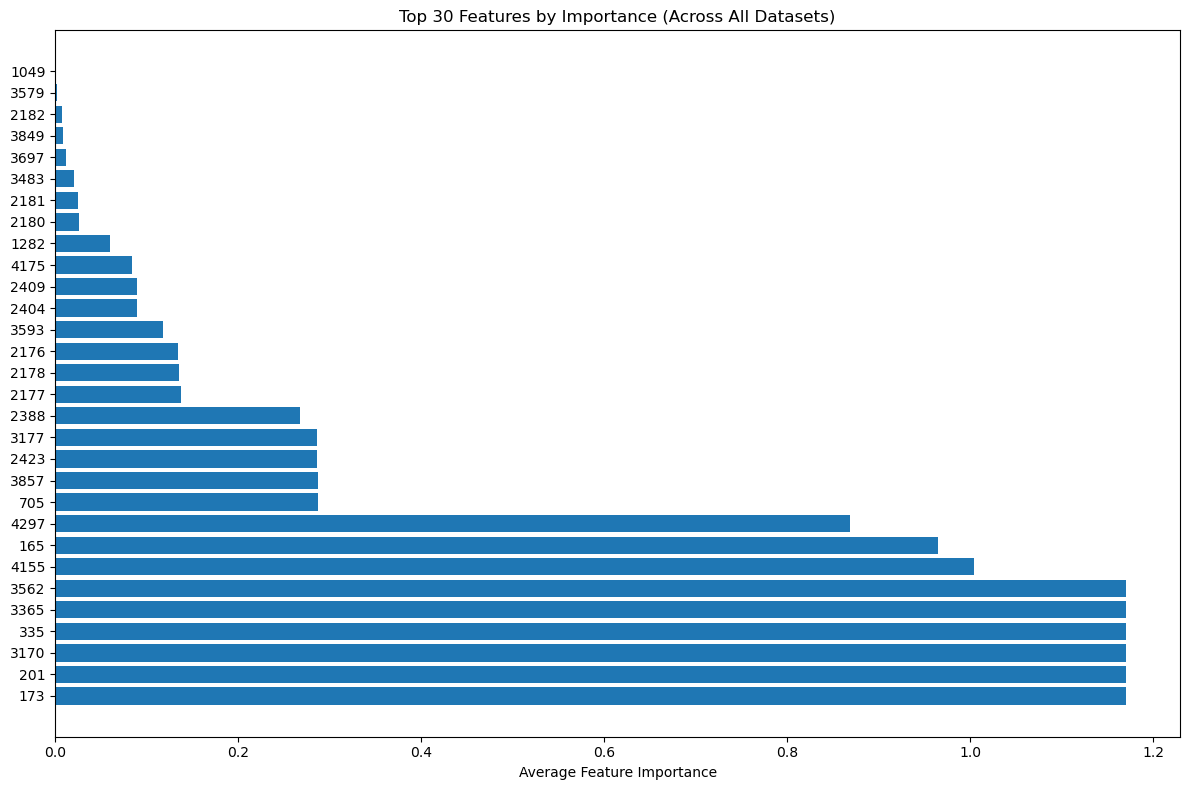

In [ ]:
# 特征重要性分析

#基础模型
# 开关: ties平滑处理重复值+two_sided双尾+门控+幂变换
# 固定使用optuna搜索FPR+trim_frac
import os
import numpy as np
import pandas as pd
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from dataclasses import dataclass, field
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    roc_auc_score,
)

# =========================
# 路径配置（按你给的）
# =========================
x = "normalization"
y = "binary"
z = "157"

benign_path = f'preprocess/dataset_0831/{x}/{y}/{z}/Benign_data.csv'
malicious_train_path = f'preprocess/dataset_0831/{x}/{y}/{z}/merged_filtered_data_train.csv'
malicious_test_path = f'preprocess/dataset_0831/{x}/{y}/{z}/merged_filtered_data_test.csv'


# =========================
# 数据读写 & 特征抽取
# =========================
def load_csv(path: str) -> pd.DataFrame:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")
    return pd.read_csv(path)


def extract_xy(df: pd.DataFrame):
    if df.shape[1] < 4:
        raise ValueError(f"Expect >=4 columns, got {df.shape[1]}")
    label_col = df.columns[1]              # 第二列标签
    feature_cols = list(df.columns[3:])    # 第四列起特征
    y = pd.to_numeric(df[label_col], errors="coerce").fillna(0).astype(int).values
    X = df.loc[:, feature_cols].copy()
    for c in feature_cols:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    return X, y, feature_cols


# =========================
# 数学/评估工具
# =========================
def fbeta(p: float, r: float, beta: float) -> float:
    p = float(p); r = float(r); beta = float(beta)
    if p <= 0 or r <= 0:
        return 0.0
    b2 = beta * beta
    return (1 + b2) * p * r / (b2 * p + r)


def threshold_under_fpr_exact(benign_scores: np.ndarray, max_fpr: float) -> float:
    """
    选择阈值 thr，使得 mean(score>=thr) <= max_fpr，且尽量紧。
    特别处理 ties：必要时用 nextafter 上抬阈值。
    """
    s = np.asarray(benign_scores, dtype=float)
    n = len(s)
    max_fpr = float(max_fpr)
    if n == 0:
        raise ValueError("Empty benign_scores")

    if max_fpr <= 0:
        return float(np.nextafter(np.max(s), np.inf))

    allowed_fp = int(np.floor(max_fpr * n))
    if allowed_fp <= 0:
        return float(np.nextafter(np.max(s), np.inf))

    s_desc = np.sort(s)[::-1]
    thr = float(s_desc[allowed_fp - 1])
    while float(np.mean(s >= thr)) > max_fpr:
        thr = float(np.nextafter(thr, np.inf))
        if thr > float(np.max(s)):
            break
    return float(thr)


def evaluate_scores(z_b: np.ndarray, z_m: np.ndarray, thr: float, beta: float):
    z_b = np.asarray(z_b, dtype=float)
    z_m = np.asarray(z_m, dtype=float)
    y_true = np.concatenate([np.zeros_like(z_b, dtype=int), np.ones_like(z_m, dtype=int)])
    y_pred = np.concatenate([(z_b >= thr).astype(int), (z_m >= thr).astype(int)])

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    fpr = float(np.mean(z_b >= thr))
    try:
        auc = float(roc_auc_score(y_true, np.concatenate([z_b, z_m])))
    except Exception:
        auc = float("nan")
    return {
        "precision": float(p),
        "recall": float(r),
        "f1": float(f1),
        f"f{beta}": float(fbeta(p, r, beta=beta)),
        "fpr": fpr,
        "auc": auc,
    }


# =========================
# 模块开关配置（用于消融）
# =========================
@dataclass(frozen=True)
class ModuleSwitches:
    use_ties: bool = True              # ties-aware
    two_sided: bool = True             # two-sided p
    use_gate_t0: bool = True           # NEW: 是否启用门控 t0
    use_power_transform: bool = True   # NEW: 是否启用幂变换 gamma


# =========================
# Detector：经验分布 + p-value + 门控 + 幂变换 + 截断 + 聚合 + 标准化
# =========================
@dataclass
class TailDetector:
    t0: float = 0.0
    gamma: float = 1.5
    trim_frac: float = 0.0

    switches: ModuleSwitches = field(default_factory=ModuleSwitches)
    eps: float = 1e-12

    feature_cols_: list = field(default_factory=list)
    sorted_benign_: list = field(default_factory=list)
    medians_: np.ndarray | None = None
    loc_: float = 0.0
    scale_: float = 1.0

    def fit(self, X_benign: pd.DataFrame, feature_cols: list):
        self.feature_cols_ = feature_cols
        X = X_benign[feature_cols].values.astype(float)

        self.medians_ = np.nanmedian(X, axis=0)
        X = np.where(np.isnan(X), self.medians_, X)

        # 良性清洗（固定：trim_frac 始终可用，由 Optuna 决定）
        if self.trim_frac and self.trim_frac > 0:
            row_stat = np.nanmax(X, axis=1)
            thr = np.quantile(row_stat, 1.0 - float(self.trim_frac))
            X = X[row_stat <= thr]

        self.sorted_benign_ = [np.sort(X[:, j]) for j in range(X.shape[1])]

        # 这里你原本没有做 loc/scale 标准化（loc_=0, scale_=1）
        # 保持原逻辑不动
        _ = self._raw_scores_from_array(X)
        self.loc_, self.scale_ = 0.0, 1.0
        return self
    
    def feature_contributions(self, X: pd.DataFrame) -> np.ndarray:
        """
        计算每个特征对每个样本的贡献值
        返回形状为 (n_samples, n_features) 的数组
        """
        X = X[self.feature_cols_].values.astype(float)
        X = np.where(np.isnan(X), self.medians_, X)
        
        n, d = X.shape
        contributions = np.zeros((n, d))
        
        for j in range(d):
            sarr = self.sorted_benign_[j]
            p = self._pvalues(sarr, X[:, j])
            u = -np.log(p)
            
            a = self._gate(u)
            
            if self.switches.use_power_transform and float(self.gamma) != 1.0:
                a = np.power(a, float(self.gamma))
                
            contributions[:, j] = a
            
        return contributions

    def _pvalues(self, sarr: np.ndarray, xcol: np.ndarray) -> np.ndarray:
        n = len(sarr)

        if self.switches.use_ties:
            lo = np.searchsorted(sarr, xcol, side="left")
            hi = np.searchsorted(sarr, xcol, side="right")
            eq = hi - lo

            left_mass = lo + 0.5 * eq
            right_mass = (n - hi) + 0.5 * eq

            p_low = (left_mass + 1.0) / (n + 2.0)
            p_up = (right_mass + 1.0) / (n + 2.0)

            p_low = np.clip(p_low, self.eps, 1.0)
            p_up = np.clip(p_up, self.eps, 1.0)

            if self.switches.two_sided:
                p = np.minimum(1.0, 2.0 * np.minimum(p_low, p_up))
            else:
                p = p_up
        else:
            idx = np.searchsorted(sarr, xcol, side="left")
            tail = (n - idx)
            p_up = (tail + 1.0) / (n + 2.0)
            p_up = np.clip(p_up, self.eps, 1.0)

            if self.switches.two_sided:
                p_low = (idx + 1.0) / (n + 2.0)
                p = np.minimum(1.0, 2.0 * np.minimum(p_low, p_up))
            else:
                p = p_up

        return np.clip(p, self.eps, 1.0)

    def _gate(self, u: np.ndarray) -> np.ndarray:
        # NEW：门控开关
        if self.switches.use_gate_t0:
            x = u - float(self.t0)
            return np.maximum(x, 0.0)
        else:
            return u

    def _raw_scores_from_array(self, X: np.ndarray) -> np.ndarray:
        n, d = X.shape
        raw = np.zeros(n, dtype=float)
        for j in range(d):
            sarr = self.sorted_benign_[j]
            p = self._pvalues(sarr, X[:, j])
            u = -np.log(p)

            a = self._gate(u)

            # NEW：幂变换开关
            if self.switches.use_power_transform and float(self.gamma) != 1.0:
                a = np.power(a, float(self.gamma))

            raw += a
        return raw

    def score_samples(self, X_any: pd.DataFrame) -> np.ndarray:
        X = X_any[self.feature_cols_].values.astype(float)
        X = np.where(np.isnan(X), self.medians_, X)
        raw = self._raw_scores_from_array(X)
        z = (raw - self.loc_) / (self.scale_ + self.eps)
        return z


# =========================
# Optuna 目标函数
# =========================
def build_objective(
    Xb_fit, Xb_cal, Xm_val, feat_cols,
    switches: ModuleSwitches,
    beta: float,
    fpr_low: float, fpr_high: float,
    fpr_penalty: float,
):
    def objective(trial: optuna.Trial) -> float:
        # 固定：始终由 Optuna 搜索 max_fpr_target
        max_fpr = trial.suggest_float("max_fpr_target", fpr_low, fpr_high, log=True)

        # detector 超参
        # 门控 t0：开关控制是否搜索/生效
        t0 = trial.suggest_float("t0", 0.0, 10.0) if switches.use_gate_t0 else 0.0

        # 幂变换 gamma：开关控制是否搜索/生效
        gamma = trial.suggest_float("gamma", 0.3, 7.0) if switches.use_power_transform else 1.0

        # 固定：trim_frac 始终由 Optuna 搜索
        trim_frac = trial.suggest_float("trim_frac", 0.0, 0.01)

        det = TailDetector(
            t0=t0,
            gamma=gamma,
            trim_frac=trim_frac,
            switches=switches
        ).fit(Xb_fit, feat_cols)

        z_b = det.score_samples(Xb_cal)
        z_m = det.score_samples(Xm_val)

        # 固定：阈值模块始终用 exact-FPR threshold
        thr = threshold_under_fpr_exact(z_b, max_fpr=max_fpr)

        metrics = evaluate_scores(z_b, z_m, thr, beta=beta)
        f1 = metrics["f1"]
        precision = metrics["precision"]

        # 仍保留你原来的“让 Optuna 不要倾向过大 FPR”的惩罚
        penalty = fpr_penalty * np.log10(max_fpr / fpr_low)

        trial.set_user_attr("f1", float(f1))
        trial.set_user_attr("fpr_target", float(max_fpr))
        trial.set_user_attr("fpr_actual", float(metrics["fpr"]))
        trial.set_user_attr("precision", float(metrics["precision"]))
        trial.set_user_attr("recall", float(metrics["recall"]))
        trial.set_user_attr("auc", float(metrics["auc"]))

        return float(f1) - penalty

    return objective


# =========================
# 单个变体的训练 + 测试
# =========================
def run_variant(
    name: str,
    Xb_fit, Xb_cal, Xb_test,
    Xm_fit, Xm_val, Xm_test,
    feat_cols,
    switches: ModuleSwitches,
    n_trials: int,
    beta: float,
    fpr_low: float,
    fpr_high: float,
    fpr_penalty: float,
    seed: int,
):
    sampler = optuna.samplers.TPESampler(seed=seed)
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=max(10, n_trials // 6))
    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)

    obj = build_objective(
        Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xm_val=Xm_val, feat_cols=feat_cols,
        switches=switches, beta=beta,
        fpr_low=fpr_low, fpr_high=fpr_high, fpr_penalty=fpr_penalty,
    )
    study.optimize(obj, n_trials=n_trials, show_progress_bar=False)

    bp = study.best_params
    best_fpr = float(bp["max_fpr_target"])

    # 最终训练 detector
    det = TailDetector(
        t0=float(bp["t0"]) if switches.use_gate_t0 else 0.0,
        gamma=float(bp["gamma"]) if switches.use_power_transform else 1.0,
        trim_frac=float(bp["trim_frac"]),
        switches=switches,
    ).fit(Xb_fit, feat_cols)

    z_b_cal = det.score_samples(Xb_cal)
    z_m_fit = det.score_samples(Xm_fit)

    thr = threshold_under_fpr_exact(z_b_cal, max_fpr=best_fpr)
    calib_metrics = evaluate_scores(z_b_cal, z_m_fit, thr, beta=beta)

    # test
    z_b_test = det.score_samples(Xb_test)
    z_m_test = det.score_samples(Xm_test)
    test_metrics = evaluate_scores(z_b_test, z_m_test, thr, beta=beta)

    y_true = np.concatenate([np.zeros(len(z_b_test), dtype=int), np.ones(len(z_m_test), dtype=int)])
    y_pred = np.concatenate([(z_b_test >= thr).astype(int), (z_m_test >= thr).astype(int)])
    cm = confusion_matrix(y_true, y_pred)
    # print(f"best_t0: {float(bp['t0']) if switches.use_gate_t0 else 0.0}")
    # print(f"best_gamma: {float(bp['gamma']) if switches.use_power_transform else 1.0}")
    # print(f"best_trim_frac: {float(bp['trim_frac'])}")


    if len(Xm_test) > 0:
        # 计算每个特征对恶意测试样本的贡献
        contrib_mal = det.feature_contributions(Xm_test)
        # 对每个特征取平均贡献（作为特征重要性）
        feature_importance = np.mean(contrib_mal, axis=0)
        # 创建特征重要性字典
        feature_importance_dict = {feat: imp for feat, imp in zip(feat_cols, feature_importance)}
    else:
        feature_importance_dict = {feat: 0.0 for feat in feat_cols}



    result = {
        "variant": name,
        "best_objective": float(study.best_value),
        "fpr_target": float(best_fpr),
        "threshold": float(thr),

        "calib_precision": calib_metrics["precision"],
        "calib_recall": calib_metrics["recall"],
        "calib_f1": calib_metrics["f1"],
        f"calib_f{beta}": calib_metrics[f"f{beta}"],
        "calib_fpr": calib_metrics["fpr"],
        "calib_auc": calib_metrics["auc"],

        "test_precision": test_metrics["precision"],
        "test_recall": test_metrics["recall"],
        "test_f1": test_metrics["f1"],
        f"test_f{beta}": test_metrics[f"f{beta}"],
        "test_fpr": test_metrics["fpr"],
        "test_auc": test_metrics["auc"],

        "test_TN": int(cm[0, 0]),
        "test_FP": int(cm[0, 1]),
        "test_FN": int(cm[1, 0]),
        "test_TP": int(cm[1, 1]),
    }

    result.update({
        "feature_importance": feature_importance_dict,
        # 标准化特征重要性（总和为1）
        "norm_feature_importance": {feat: imp/sum(feature_importance) 
                                   for feat, imp in feature_importance_dict.items()}
    })

    return result


# =========================
# 特征重要性分析主函数
# =========================
def analyze_feature_importance(
    x_values: list = ["test_camp", "test_keytrap", "test_nxns", "test_camp+nxns"],
    n_trials_full: int = 2,
    beta: float = 4.0,
    fpr_low: float = 3e-5,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
    output_dir: str = "feature_importance"
):
    """
    分析多个数据集的特征重要性并排序
    
    参数:
        x_values: 数据集列表
        其他参数与evaluate_multiple_datasets_with_proper_split一致
        output_dir: 输出目录
    
    返回:
        sorted_features: 按重要性排序的特征列表 [(feature, importance), ...]
        importance_df: 特征重要性DataFrame
    """
    y = "normalization"
    z = "157"
    
    # 确保输出目录存在
    os.makedirs(output_dir, exist_ok=True)
    
    # 收集所有数据集的特征重要性
    dataset_feature_importances = {}
    all_features = set()
    dataset_results = []
    
    # 首先收集所有特征（用于后续对齐）
    for x in x_values:
        # 设置路径
        benign_path = f'preprocess/dataset_0831/{y}/binary/{z}/Benign_data.csv'
        malicious_train_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_train.csv'
        malicious_test_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_test.csv'
        
        try:
            # 加载数据
            benign_df = load_csv(benign_path)
            mal_train_df = load_csv(malicious_train_path)
            mal_test_df = load_csv(malicious_test_path)
            
            Xb, yb, feat_cols_b = extract_xy(benign_df)
            Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
            Xm_te, ym_te, _ = extract_xy(mal_test_df)
            
            # 特征对齐
            feat_cols = [c for c in feat_cols_b if c in Xm_tr.columns and c in Xm_te.columns]
            all_features.update(feat_cols)
            
        except Exception as e:
            print(f"Error processing dataset {x}: {str(e)}")
            continue
    
    # 如果没有特征，直接返回
    if not all_features:
        print("No features found across datasets.")
        return [], pd.DataFrame()
    
    # 将特征集转换为排序列表（确保一致性）
    all_features = sorted(all_features)
    
    # 处理每个数据集
    for i, x in enumerate(x_values):
        print(f"\n--- [{i+1}/{len(x_values)}] Analyzing feature importance for: {x} ---")
        
        # 设置路径
        benign_path = f'preprocess/dataset_0831/{y}/binary/{z}/Benign_data.csv'
        malicious_train_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_train.csv'
        malicious_test_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_test.csv'
        
        try:
            # 加载数据
            benign_df = load_csv(benign_path)
            mal_train_df = load_csv(malicious_train_path)
            mal_test_df = load_csv(malicious_test_path)
            
            Xb, yb, feat_cols_b = extract_xy(benign_df)
            Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
            Xm_te, ym_te, _ = extract_xy(mal_test_df)
            
            # 特征对齐
            feat_cols = [c for c in feat_cols_b if c in Xm_tr.columns and c in Xm_te.columns]
            if len(feat_cols) == 0:
                raise ValueError("No common feature columns among datasets.")
            
            Xb = Xb[feat_cols]
            Xm_tr = Xm_tr[feat_cols]
            Xm_te = Xm_te[feat_cols]
            
            # 仅保留恶意样本
            Xm_train_mal = Xm_tr[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr
            Xm_test_mal = Xm_te[ym_te == 1] if np.any(ym_te == 1) else Xm_te

            # 数据划分
            Xb_fit, Xb_tmp = train_test_split(Xb, test_size=0.30, random_state=seed, shuffle=True)
            Xb_cal, Xb_test = train_test_split(Xb_tmp, test_size=0.50, random_state=seed, shuffle=True)
            
            if len(Xm_train_mal) >= 20:
                Xm_fit, Xm_val = train_test_split(Xm_train_mal, test_size=0.30, random_state=seed, shuffle=True)
            else:
                Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal
            
            # 为当前数据集运行变体（获取最佳参数）
            switches = ModuleSwitches(True, True, True, True)
            result = run_variant(
                name=f"{x}_FULL",
                Xb_fit=Xb_fit,
                Xb_cal=Xb_cal,
                Xb_test=Xb_test,
                Xm_fit=Xm_fit,
                Xm_val=Xm_val,
                Xm_test=Xm_test_mal,
                feat_cols=feat_cols,
                switches=switches,
                n_trials=n_trials_full,
                beta=beta,
                fpr_low=fpr_low,
                fpr_high=fpr_high,
                fpr_penalty=fpr_penalty,
                seed=seed,
            )
            
            # 检查是否有特征重要性
            if "feature_importance" not in result:
                print(f"  No feature importance data for {x}")
                continue
            
            # 收集特征重要性
            fi_dict = result["feature_importance"]
            dataset_feature_importances[x] = fi_dict
            
            # 保存数据集级别的特征重要性
            dataset_fi = []
            for feat in all_features:
                imp = fi_dict.get(feat, 0.0)  # 如果特征不存在，设为0
                dataset_fi.append({"feature": feat, "importance": imp})
            
            # 按重要性排序
            dataset_fi_sorted = sorted(dataset_fi, key=lambda x: x["importance"], reverse=True)
            dataset_results.append({
                "dataset": x,
                "top_features": [item["feature"] for item in dataset_fi_sorted[:10]],  # 前10个特征
                "top_importances": [item["importance"] for item in dataset_fi_sorted[:10]]
            })
            
            # 保存到CSV
            dataset_df = pd.DataFrame(dataset_fi_sorted)
            dataset_df.to_csv(f"{output_dir}/{x}_importance.csv", index=False)
            print(f"  Saved dataset feature importance to {output_dir}/{x}_importance.csv")
            
        except Exception as e:
            print(f"  ERROR processing {x} for feature importance: {str(e)}")
            continue
    
    # 汇总特征重要性（跨数据集）
    if not dataset_feature_importances:
        print("No feature importance data collected.")
        return [], pd.DataFrame()
    
    # 计算每个特征的平均重要性
    total_importance = {feat: 0.0 for feat in all_features}
    count = {feat: 0 for feat in all_features}
    
    for x, fi_dict in dataset_feature_importances.items():
        for feat, imp in fi_dict.items():
            total_importance[feat] += imp
            count[feat] += 1
    
    # 计算平均重要性
    avg_importance = {}
    for feat in all_features:
        if count[feat] > 0:
            avg_importance[feat] = total_importance[feat] / count[feat]
    
    # 按重要性排序
    sorted_features = sorted(avg_importance.items(), key=lambda x: x[1], reverse=True)
    
    # 创建DataFrame用于保存
    importance_data = []
    for i, (feat, imp) in enumerate(sorted_features):
        importance_data.append({
            "rank": i+1,
            "feature": feat,
            "importance": imp,
            "occurrence": count[feat],
            "relative_importance": imp / max(avg_importance.values()) if max(avg_importance.values()) > 0 else 0
        })
    
    importance_df = pd.DataFrame(importance_data)
    
    # 保存总体特征重要性
    importance_df.to_csv(f"{output_dir}/overall_importance.csv", index=False)
    
    # 打印结果
    print("\n" + "="*80)
    print("AGGREGATED FEATURE IMPORTANCE (SORTED):")
    print("="*80)
    print(f"{'Rank':<5} {'Feature':<30} {'Importance':<12} {'Occurrence':<10} {'Rel. Imp.':<10}")
    print("-"*75)
    
    for i, (feat, imp) in enumerate(sorted_features[:50]):  # 显示前50个
        rel_imp = imp / max(avg_importance.values()) if max(avg_importance.values()) > 0 else 0
        print(f"{i+1:<5} {feat:<30} {imp:<12.6f} {count[feat]:<10} {rel_imp:<10.2%}")
    
    print(f"\nFeature importance saved to '{output_dir}/' directory")

    
    return sorted_features, importance_df, pd.DataFrame(dataset_results)


if __name__ == "__main__":
    # 运行特征重要性分析
    sorted_features, importance_df, dataset_results = analyze_feature_importance(
        x_values=["test_camp", "test_nxns", "test_SigJam", "test_LockCram", "test_KeySigTrap"],
        n_trials_full=100,
        beta=1.0,
        fpr_low=3e-5,
        fpr_high=2e-2,
        fpr_penalty=0.03,
        seed=42,
        output_dir="feature_importance"
    )
    
    # 打印最重要的10个特征
    print("\nTop 10 Most Important Features:")
    for i, (feat, imp) in enumerate(sorted_features[:10]):
        print(f"{i+1}. {feat}: {imp:.6f}")


In [9]:
def run_ablation_suite_across_datasets(
    x_values: list = ["test_camp", "test_keytrap", "test_nxns", "test_camp+nxns"],
    n_trials: int = 20,
    feature_trials: int = 20,
    beta: float = 4.0,
    fpr_low: float = 1e-4,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    seed: int = 42,
    save_csv: str = "ablation_results_across_datasets.csv",
):
    """
    修改版：先随机选择特征，然后用同一特征子集处理所有数据集
    1. 为每个特征数量n_features进行feature_trials次试验
    2. 每次试验：随机选择特征子集 → 处理所有数据集 → 合并混淆矩阵
    3. 基于全局混淆矩阵计算指标
    4. 统计多次试验的指标分布
    """
    # 固定配置
    y = "normalization"
    z = "157"
    
    # 步骤1: 计算所有数据集共有的特征（关键修改）
    print("Calculating common features across all datasets...")
    benign_path = f'preprocess/dataset_0831/{y}/binary/{z}/Benign_data.csv'
    benign_df = load_csv(benign_path)
    _, _, feat_cols_b = extract_xy(benign_df)
    common_feat = set(feat_cols_b)
    
    # 检查所有恶意数据集的特征
    for x in x_values:
        malicious_train_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_train.csv'
        malicious_test_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_test.csv'
        try:
            mal_train_df = load_csv(malicious_train_path)
            mal_test_df = load_csv(malicious_test_path)
            _, _, feat_cols_mal_tr = extract_xy(mal_train_df)
            _, _, feat_cols_mal_te = extract_xy(mal_test_df)
            common_feat = common_feat & set(feat_cols_mal_tr) & set(feat_cols_mal_te)
        except Exception as e:
            print(f"  !!! Error loading {x}: {str(e)}")
    
    feat_cols = list(common_feat)
    if len(feat_cols) < 17:
        raise ValueError(f"Insufficient common features ({len(feat_cols)}) across datasets. Need at least 17.")
    
    print(f"  Found {len(feat_cols)} common features across all datasets")
    
    # 步骤2: 预加载良性数据（所有数据集共享）
    benign_df = load_csv(benign_path)
    Xb_all, yb_all, _ = extract_xy(benign_df)
    # 只保留共有的特征
    Xb_all = Xb_all[feat_cols]
    
    # 步骤3: 设置特征数量范围
    max_features = min(157, len(feat_cols))
    feature_numbers = range(17, max_features + 1, 70)
    print(f"Testing feature counts: {list(feature_numbers)}")
    
    all_results = []
    
    # 遍历每个特征数量
    for n_features in feature_numbers:
        print(f"\n{'='*50}")
        print(f"Testing {n_features} features across {len(x_values)} datasets")
        print(f"{'='*50}")
        
        # 存储每次试验的全局指标
        global_f1_scores = []
        global_f_beta_scores = []
        global_accuracy_scores = []
        global_precision_scores = []
        global_recall_scores = []
        
        # 进行多次特征选择试验
        for trial_idx in range(feature_trials):
            # ===== 关键修改1: 先随机选择特征子集 =====
            selected_features = np.random.choice(
                feat_cols, 
                size=n_features, 
                replace=False
            )
            # print(f"\nTrial {trial_idx+1}/{feature_trials}: Using {len(selected_features)} features")
            # print(f"Selected features: {selected_features[:5]}... (total {len(selected_features)})")
            
            # ===== 关键修改2: 初始化全局混淆矩阵 =====
            global_TN, global_FP, global_FN, global_TP = 0, 0, 0, 0
            
            # 遍历所有数据集，使用相同的特征子集
            for i, x in enumerate(x_values):
                # print(f"  Processing dataset [{i+1}/{len(x_values)}]: {x}")
                
                # 加载恶意数据
                malicious_train_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_train.csv'
                malicious_test_path = f'preprocess/dataset_fanhua_new/{y}/{z}/{x}/merged_filtered_data_test.csv'
                
                try:
                    mal_train_df = load_csv(malicious_train_path)
                    mal_test_df = load_csv(malicious_test_path)
                    
                    # 提取特征（只保留selected_features）
                    Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
                    Xm_te, ym_te, _ = extract_xy(mal_test_df)
                    Xm_tr_selected = Xm_tr[selected_features]
                    Xm_te_selected = Xm_te[selected_features]
                    
                    # ===== 关键修改3: 使用相同随机种子进行划分（保证可重现性） =====
#                    current_seed = seed + trial_idx + n_features + i
                    current_seed = seed
 
                    # 良性数据划分（使用预加载的Xb_all）
                    Xb_selected = Xb_all[selected_features]
                    Xb_fit, Xb_tmp = train_test_split(
                        Xb_selected, 
                        test_size=0.30, 
                        random_state=current_seed, 
                        shuffle=True
                    )
                    Xb_cal, Xb_test = train_test_split(
                        Xb_tmp, 
                        test_size=0.50, 
                        random_state=current_seed, 
                        shuffle=True
                    )
                    
                    # 恶意训练数据划分
                    Xm_train_mal = Xm_tr_selected[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr_selected
                    if len(Xm_train_mal) >= 20:
                        Xm_fit, Xm_val = train_test_split(
                            Xm_train_mal, 
                            test_size=0.30, 
                            random_state=current_seed, 
                            shuffle=True
                        )
                    else:
                        Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal
                    
                    # 恶意测试数据
                    Xm_test_mal = Xm_te_selected[ym_te == 1] if np.any(ym_te == 1) else Xm_te_selected
                    
                    # 运行模型评估
                    switches = ModuleSwitches(True, True, True, True)
                    result = run_variant(
                        name=f"global_ablation_{n_features}_{trial_idx}_{x}",
                        Xb_fit=Xb_fit,
                        Xb_cal=Xb_cal,
                        Xb_test=Xb_test,
                        Xm_fit=Xm_fit,
                        Xm_val=Xm_val,
                        Xm_test=Xm_test_mal,
                        feat_cols=selected_features,
                        switches=switches,
                        n_trials=n_trials,
                        beta=beta,
                        fpr_low=fpr_low,
                        fpr_high=fpr_high,
                        fpr_penalty=fpr_penalty,
                        seed=current_seed,
                    )
                    
                    # 累加混淆矩阵
                    global_TN += result["test_TN"]
                    global_FP += result["test_FP"]
                    global_FN += result["test_FN"]
                    global_TP += result["test_TP"]
                    
    #                print(f"    Dataset {x} | TP: {result['test_TP']}, FP: {result['test_FP']}")
                    
                except Exception as e:
                    print(f"  !!! Error processing {x}: {str(e)}")
                    continue
            
            # ===== 关键修改4: 基于全局混淆矩阵计算指标 =====
            total = global_TN + global_FP + global_FN + global_TP
            if total == 0:
                accuracy = precision = recall = f1 = f_beta = 0.0
            else:
                accuracy = (global_TN + global_TP) / total
                precision = global_TP / (global_TP + global_FP) if (global_TP + global_FP) > 0 else 0
                recall = global_TP / (global_TP + global_FN) if (global_TP + global_FN) > 0 else 0
                f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
                
                # 计算F_beta
                beta_sq = beta ** 2
                f_beta = (1 + beta_sq) * (precision * recall) / (beta_sq * precision + recall) if (beta_sq * precision + recall) > 0 else 0
            
            # 记录本次试验的全局指标
            global_f1_scores.append(f1)
            global_f_beta_scores.append(f_beta)
            global_accuracy_scores.append(accuracy)
            global_precision_scores.append(precision)
            global_recall_scores.append(recall)
            
            print(f"\n  Trial {trial_idx+1} GLOBAL RESULTS (all datasets):")
            print(f"    Accuracy: {accuracy:.4f} | F{beta}: {f_beta:.4f} | F1: {f1:.4f}")
            print(f"    Precision: {precision:.4f} | Recall: {recall:.4f}")
            print(f"    Confusion Matrix: TN={global_TN}, FP={global_FP}, FN={global_FN}, TP={global_TP}")
        
        # ===== 关键修改5: 计算统计指标 =====
        def calc_stats(arr):
            arr = np.array(arr)
            return (
                np.max(arr) if len(arr) > 0 else 0,
                np.min(arr) if len(arr) > 0 else 0,
                np.mean(arr) if len(arr) > 0 else 0,
                np.var(arr) if len(arr) > 0 else 0
            )
        
        stats = {
            'f1': calc_stats(global_f1_scores),
            'f_beta': calc_stats(global_f_beta_scores),
            'acc': calc_stats(global_accuracy_scores),
            'pre': calc_stats(global_precision_scores),
            'rec': calc_stats(global_recall_scores)
        }
        
        # 保存结果
        result_entry = {
            "n_features": n_features,
            "f1_max": stats['f1'][0],
            "f1_min": stats['f1'][1],
            "f1_mean": stats['f1'][2],
            "f1_var": stats['f1'][3],
            f"f{beta}_max": stats['f_beta'][0],
            f"f{beta}_min": stats['f_beta'][1],
            f"f{beta}_mean": stats['f_beta'][2],
            f"f{beta}_var": stats['f_beta'][3],
            "accuracy_max": stats['acc'][0],
            "accuracy_min": stats['acc'][1],
            "accuracy_mean": stats['acc'][2],
            "accuracy_var": stats['acc'][3],
            "precision_max": stats['pre'][0],
            "precision_min": stats['pre'][1],
            "precision_mean": stats['pre'][2],
            "precision_var": stats['pre'][3],
            "recall_max": stats['rec'][0],
            "recall_min": stats['rec'][1],
            "recall_mean": stats['rec'][2],
            "recall_var": stats['rec'][3],
        }
        all_results.append(result_entry)
        
        # 打印汇总
        print(f"\n{'-'*50}")
        print(f"Results for {n_features} features (across {feature_trials} trials):")
        print(f"  F{beta}: mean={stats['f_beta'][2]:.4f} | max={stats['f_beta'][0]:.4f} | min={stats['f_beta'][1]:.4f}")
        print(f"  F1:    mean={stats['f1'][2]:.4f} | max={stats['f1'][0]:.4f} | min={stats['f1'][1]:.4f}")
        print(f"  Acc:   mean={stats['acc'][2]:.4f}")
        print(f"{'-'*50}")
    
    # 保存结果
    if all_results:
        df = pd.DataFrame(all_results)
        if save_csv:
            df.to_csv(save_csv, index=False)
            print(f"\nResults saved to: {save_csv}")
            print(f"Total configurations: {len(df)}")
        return df
    else:
        print("\n!!! NO VALID RESULTS GENERATED !!!")
        return pd.DataFrame()

if __name__ == "__main__":
    # 使用代码A中的数据集列表
    x_values = [
        "test_camp", 
        "test_nxns", 
        "test_keytrap"
        # "test_LockCram", 
        # "test_KeySigTrap"
    ]
    
    # 运行跨数据集特征消融实验
    results_df = run_ablation_suite_across_datasets(
        x_values=x_values,
        n_trials=50,
        feature_trials=20,  # 增加到20次试验以获得更可靠的统计
        beta=1,
        fpr_low=5e-5,
        fpr_high=2e-2,
        fpr_penalty=0.03,
        seed=42,
        save_csv="global_ablation_results.csv"
    )
    
    # 打印结果摘要
    if not results_df.empty:
        print("\n=== FINAL RESULTS SUMMARY ===")
        print(results_df[[
            "n_features", 
            "f1_mean", 
            f"f{1}_mean", 
            "accuracy_mean",
            "precision_mean",
            "recall_mean"
        ]])

Calculating common features across all datasets...
  Found 157 common features across all datasets
Testing feature counts: [17, 87, 157]

Testing 17 features across 3 datasets

  Trial 1 GLOBAL RESULTS (all datasets):
    Accuracy: 0.9798 | F1: 0.7909 | F1: 0.7909
    Precision: 0.9110 | Recall: 0.6988
    Confusion Matrix: TN=18915, FP=75, FN=331, TP=768

  Trial 2 GLOBAL RESULTS (all datasets):
    Accuracy: 0.9401 | F1: 0.0505 | F1: 0.0505
    Precision: 0.1905 | Recall: 0.0291
    Confusion Matrix: TN=18854, FP=136, FN=1067, TP=32

  Trial 3 GLOBAL RESULTS (all datasets):
    Accuracy: 0.9838 | F1: 0.8359 | F1: 0.8359
    Precision: 0.9388 | Recall: 0.7534
    Confusion Matrix: TN=18936, FP=54, FN=271, TP=828

  Trial 4 GLOBAL RESULTS (all datasets):
    Accuracy: 0.9922 | F1: 0.9301 | F1: 0.9301
    Precision: 0.9110 | Recall: 0.9500
    Confusion Matrix: TN=18888, FP=102, FN=55, TP=1044

  Trial 5 GLOBAL RESULTS (all datasets):
    Accuracy: 0.9961 | F1: 0.9653 | F1: 0.9653
    P

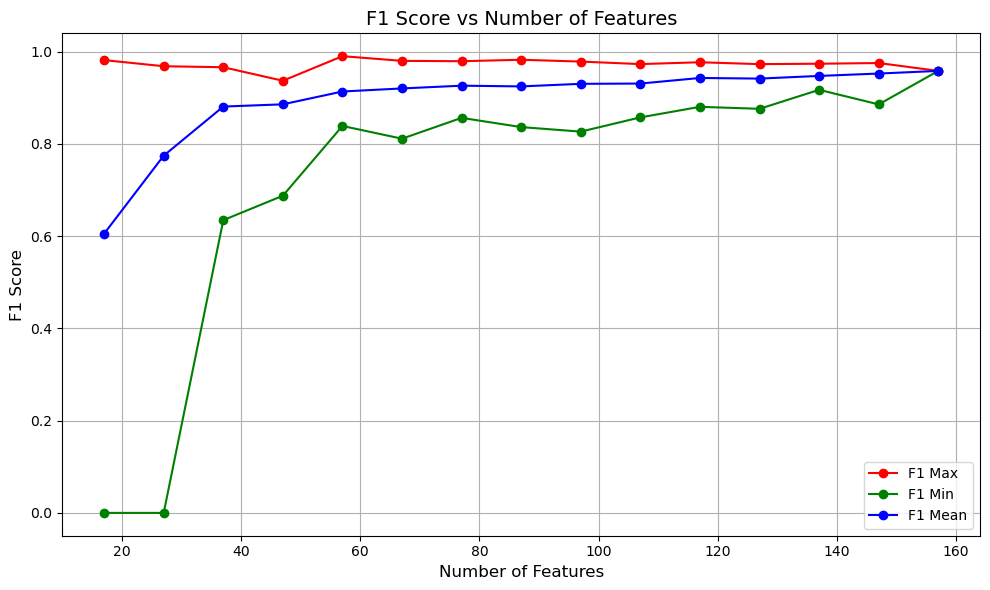

In [ ]:
# 分别绘制准确率、精确率、召回率和F1的折线图
import pandas as pd
import matplotlib.pyplot as plt

# 读取ablation_results_varying_features.csv文件
df = pd.read_csv('ablation_results_varying_features.csv')

# 提取横坐标（特征数量）
feature_numbers = df['n_features']

# 提取纵坐标（f1最大值、最小值、平均值）
f1_max = df['f1_max']
f1_min = df['f1_min']
f1_mean = df['f1_mean']

# 创建一个折线图
plt.figure(figsize=(10, 6))

# 绘制f1的最大值、最小值和平均值的折线
plt.plot(feature_numbers, f1_max, label='F1 Max', marker='o', linestyle='-', color='r')
plt.plot(feature_numbers, f1_min, label='F1 Min', marker='o', linestyle='-', color='g')
plt.plot(feature_numbers, f1_mean, label='F1 Mean', marker='o', linestyle='-', color='b')

# 设置图表标题和标签
plt.title('F1 Score vs Number of Features', fontsize=14)
plt.xlabel('Number of Features', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)

# 添加图例
plt.legend()

# 显示图表
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Generalization Experiments
# 泛化实验

def run_ablation_suite_Generalization(
    n_trials_full: int = 80,
    n_trials_ablation: int = 50,
    beta: float = 4.0,
    fpr_low: float = 1e-4,
    fpr_high: float = 2e-2,
    fpr_penalty: float = 0.03,
    fixed_fpr: float = 1e-3,
    seed: int = 42,
    save_csv: str = "ablation_results.csv",
    malicious_train_path: str = "preprocess/dataset_0831/normalization/binary/157/merged_filtered_data_train.csv",  
    malicious_test_path: str = "preprocess/dataset_0831/normalization/binary/157/merged_filtered_data_test.csv",  
):
    benign_df = load_csv(benign_path)
    mal_train_df = load_csv(malicious_train_path)  # Using custom path
    mal_test_df = load_csv(malicious_test_path)    # Using custom path

    Xb, yb, feat_cols_b = extract_xy(benign_df)
    Xm_tr, ym_tr, _ = extract_xy(mal_train_df)
    Xm_te, ym_te, _ = extract_xy(mal_test_df)

    feat_cols = [c for c in feat_cols_b if c in Xm_tr.columns and c in Xm_te.columns]
    if len(feat_cols) == 0:
        raise ValueError("No common feature columns among datasets.")

    Xb = Xb[feat_cols]
    Xm_tr = Xm_tr[feat_cols]
    Xm_te = Xm_te[feat_cols]

    Xm_train_mal = Xm_tr[ym_tr == 1] if np.any(ym_tr == 1) else Xm_tr
    Xm_test_mal = Xm_te[ym_te == 1] if np.any(ym_te == 1) else Xm_te

    Xb_fit, Xb_tmp = train_test_split(Xb, test_size=0.30, random_state=seed, shuffle=True)
    Xb_cal, Xb_test = train_test_split(Xb_tmp, test_size=0.50, random_state=seed, shuffle=True)

    if len(Xm_train_mal) >= 20:
        Xm_fit, Xm_val = train_test_split(Xm_train_mal, test_size=0.30, random_state=seed, shuffle=True)
    else:
        Xm_fit, Xm_val = Xm_train_mal, Xm_train_mal

    print("==== Data Summary ====")
    print(f"n_features: {len(feat_cols)}")
    print(f"benign_fit={len(Xb_fit)}, benign_calib={len(Xb_cal)}, benign_test={len(Xb_test)}")
    print(f"mal_fit={len(Xm_fit)}, mal_val={len(Xm_val)}, mal_test={len(Xm_test_mal)}")
    print(f"FPR search range=[{fpr_low}, {fpr_high}] when optimize_fpr=True; fixed_fpr={fixed_fpr}\n")

    variants = [
        ("FULL", ModuleSwitches(True, True, True, True), n_trials_full),
    ]

    results = []
    for name, sw, ntr in variants:
        print(f"=== Running Variant: {name} (trials={ntr}) ===")
        res = run_variant(
                name=name,
                Xb_fit=Xb_fit, Xb_cal=Xb_cal, Xb_test=Xb_test,
                Xm_fit=Xm_fit, Xm_val=Xm_val, Xm_test=Xm_test_mal,
                feat_cols=feat_cols,
                switches=sw,
                n_trials=ntr,
                beta=beta,
                fpr_low=fpr_low,
                fpr_high=fpr_high,
                fpr_penalty=fpr_penalty,
                seed=seed,
            )
        results.append(res)

        print(f"  fpr_target={res['fpr_target']:.6g}, thr={res['threshold']:.6f}")
        print(f"  CALIB: P={res['calib_precision']:.4f} R={res['calib_recall']:.4f} F1={res['calib_f1']:.4f} FPR={res['calib_fpr']:.6f} AUC={res['calib_auc']:.4f}")
        print(f"  TEST : P={res['test_precision']:.4f} R={res['test_recall']:.4f} F1={res['test_f1']:.4f} FPR={res['test_fpr']:.6f} AUC={res['test_auc']:.4f}")
        print(f"  CM   : TN={res['test_TN']} FP={res['test_FP']} FN={res['test_FN']} TP={res['test_TP']}\n")

    df = pd.DataFrame(results)
    fbeta_col = f"test_f{beta}"
    df = df.sort_values(by=[fbeta_col, "test_f1", "test_recall"], ascending=False)

    print("==== Ablation Summary (sorted) ====")
    cols_show = [
        "variant", "fpr_target", "threshold",
        "test_precision", "test_recall", "test_f1", f"test_f{beta}", "test_fpr", "test_auc",
        "test_TN", "test_FP", "test_FN", "test_TP",
    ]
    print(df[cols_show].to_string(index=False))

    if save_csv:
        df.to_csv(save_csv, index=False)
        print(f"\nSaved to: {save_csv}")

    return df
x = "normalization"
y = "binary"
z = "157"

benign_path = f'preprocess/dataset_0831/{x}/{y}/{z}/Benign_data.csv'

if __name__ == "__main__":
    
    y = "normalization"
    z = "157"

    # Initialize an empty list to store the results
    all_results = []

    # Define the x values for each run
    x_values = ["test_camp", "test_keytrap", "test_nxns", "test_camp+nxns"]
#    x_values = ["test_keytrap", "test_camp+nxns"]

    # Iterate through each x value and run the ablation suite
    for x in x_values:
        print(f"Running ablation suite for {x}...")
  
        # Run the ablation suite and collect the result
        result = run_ablation_suite_Generalization(
            n_trials_full=80,
            n_trials_ablation=10,
            beta=1.0,
            fpr_low=3e-5,
            fpr_high=2e-2,
            fpr_penalty=0.03,
            fixed_fpr=1e-3,
            seed=42,
            save_csv=None,  # We don't want to save a separate CSV each time
            malicious_train_path=f'preprocess/dataset_fanhua/{y}/{z}/{x}/merged_filtered_data_train.csv',
            malicious_test_path=f'preprocess/dataset_fanhua/{y}/{z}/{x}/merged_filtered_data_test.csv',
        )
        
        # Extract the metrics you're interested in (accuracy, precision, recall, F1)
        best_result = result.iloc[0]  # Get the best result (sorted by fbeta, f1, recall)
        
        # Prepare the row to append: [x, accuracy, precision, recall, F1]
        row = {
            'x': x,
            'accuracy': round(best_result['test_auc'], 4),  # Round to 4 decimal places
            'precision': round(best_result['test_precision'], 4),  # Round to 4 decimal places
            'recall': round(best_result['test_recall'], 4),  # Round to 4 decimal places
            'f1': round(best_result['test_f1'], 4)  # Round to 4 decimal places
  }

        # Append the row to the list of all results
        all_results.append(row)

    # Convert the list of results to a DataFrame
    results_df = pd.DataFrame(all_results)

    # Save the results to a CSV file
    results_df.to_csv("ablation_results.csv", index=False)

    print("\nAblation results saved to 'ablation_results.csv'")


Running ablation suite for test_keytrap...


[I 2025-12-29 15:31:15,094] A new study created in memory with name: no-name-5a0cba66-5909-4faa-bb06-79c373153810


==== Data Summary ====
n_features: 157
benign_fit=29537, benign_calib=6329, benign_test=6330
mal_fit=350, mal_val=150, mal_test=404
FPR search range=[3e-05, 0.02] when optimize_fpr=True; fixed_fpr=0.001

=== Running Variant: FULL (trials=50) ===


[I 2025-12-29 15:31:15,949] Trial 0 finished with value: 0.18756823215061336 and parameters: {'max_fpr_target': 0.00034260079796816814, 't0': 9.50714306409916, 'gamma': 5.204359410136414, 'trim_frac': 0.0017959754525911098}. Best is trial 0 with value: 0.18756823215061336.
[I 2025-12-29 15:31:16,781] Trial 1 finished with value: 0.15872822928259672 and parameters: {'max_fpr_target': 8.273774063732907e-05, 't0': 1.5599452033620265, 'gamma': 0.6891602015269365, 'trim_frac': 0.0025985284373248054}. Best is trial 0 with value: 0.18756823215061336.
[I 2025-12-29 15:31:17,628] Trial 2 finished with value: 0.6724136672376122 and parameters: {'max_fpr_target': 0.0014949104944281947, 't0': 7.080725777960454, 'gamma': 0.4379161117818764, 'trim_frac': 0.002909729556485983}. Best is trial 2 with value: 0.6724136672376122.
[I 2025-12-29 15:31:18,482] Trial 3 finished with value: 0.8390131908320059 and parameters: {'max_fpr_target': 0.006727648680429294, 't0': 2.1233911067827616, 'gamma': 1.51822728

  fpr_target=0.00541316, thr=6.326501
  CALIB: P=0.9108 R=0.9914 F1=0.9494 FPR=0.005372 AUC=0.9990
  TEST : P=0.9161 R=1.0000 F1=0.9562 FPR=0.005845 AUC=0.9982
  CM   : TN=6293 FP=37 FN=0 TP=404

==== Ablation Summary (sorted) ====
variant  fpr_target  threshold  test_precision  test_recall  test_f1  test_f4.0  test_fpr  test_auc  test_TN  test_FP  test_FN  test_TP
   FULL    0.005413   6.326501          0.9161          1.0 0.956213   0.994642  0.005845  0.998195     6293       37        0      404
Running ablation suite for test_camp+nxns...


[I 2025-12-29 15:31:58,959] A new study created in memory with name: no-name-fe5a7e93-8727-44c0-8aaf-dae4c35a95ac


==== Data Summary ====
n_features: 157
benign_fit=29537, benign_calib=6329, benign_test=6330
mal_fit=282, mal_val=122, mal_test=500
FPR search range=[3e-05, 0.02] when optimize_fpr=True; fixed_fpr=0.001

=== Running Variant: FULL (trials=50) ===


[I 2025-12-29 15:31:59,798] Trial 0 finished with value: 0.7287638136970721 and parameters: {'max_fpr_target': 0.00034260079796816814, 't0': 9.50714306409916, 'gamma': 5.204359410136414, 'trim_frac': 0.0017959754525911098}. Best is trial 0 with value: 0.7287638136970721.
[I 2025-12-29 15:32:00,648] Trial 1 finished with value: 0.4716310127736155 and parameters: {'max_fpr_target': 8.273774063732907e-05, 't0': 1.5599452033620265, 'gamma': 0.6891602015269365, 'trim_frac': 0.0025985284373248054}. Best is trial 0 with value: 0.7287638136970721.
[I 2025-12-29 15:32:01,489] Trial 2 finished with value: 0.8579712162187287 and parameters: {'max_fpr_target': 0.0014949104944281947, 't0': 7.080725777960454, 'gamma': 0.4379161117818764, 'trim_frac': 0.002909729556485983}. Best is trial 2 with value: 0.8579712162187287.
[I 2025-12-29 15:32:02,344] Trial 3 finished with value: 0.8891706367818203 and parameters: {'max_fpr_target': 0.006727648680429294, 't0': 2.1233911067827616, 'gamma': 1.518227280287

  fpr_target=0.00318153, thr=59.941082
  CALIB: P=0.9203 R=0.8191 F1=0.8668 FPR=0.003160 AUC=0.9986
  TEST : P=0.9632 R=0.9940 F1=0.9783 FPR=0.003002 AUC=0.9993
  CM   : TN=6311 FP=19 FN=3 TP=497

==== Ablation Summary (sorted) ====
variant  fpr_target  threshold  test_precision  test_recall  test_f1  test_f4.0  test_fpr  test_auc  test_TN  test_FP  test_FN  test_TP
   FULL    0.003182  59.941082        0.963178        0.994 0.978346   0.992132  0.003002  0.999346     6311       19        3      497

Ablation results saved to 'ablation_results.csv'


In [ ]:
# 7个机器学习+3个深度学习模型
# 未知攻击检测

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, balanced_accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import layers, models

# =====================================================
# 1. 加载数据
# =====================================================
BENIGN_PATH = 'preprocess/dataset_0831/normalization/binary/157/Benign_data.csv'
MAL_TRAIN_PATH = 'preprocess/dataset_0831/normalization/binary/157/merged_filtered_data_test.csv'
MAL_TEST_PATH  = 'preprocess/dataset_0831/normalization/binary/157/merged_filtered_data_train.csv'

def load_dataset(path):
    df = pd.read_csv(path)
    X = df.iloc[:, 3:160].values  # 20 features
    y = df.iloc[:, 1].values     # label
    return X, y

X_benign, y_benign = load_dataset(BENIGN_PATH)
X_mal_train, y_mal_train = load_dataset(MAL_TRAIN_PATH)
X_mal_test,  y_mal_test  = load_dataset(MAL_TEST_PATH)

# 良性数据拆分
X_ben_train, X_ben_test, y_ben_train, y_ben_test = train_test_split(
    X_benign, y_benign, test_size=0.3, random_state=42
)

# ============================
# 2. 训练 / 测试集构造
# ============================
X_train = np.vstack([X_ben_train, X_mal_train])
y_train = np.hstack([y_ben_train, y_mal_train])

X_test = np.vstack([X_ben_test, X_mal_test])
y_test = np.hstack([y_ben_test, y_mal_test])

# 标准化
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

# =====================================================
# 3. 定义评估函数
# =====================================================
def evaluate_model(name, y_true, y_pred, results):
    cm = confusion_matrix(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(f"\n========== {name} ==========")
    print("Confusion Matrix:\n", cm)
    print(f"Balanced Acc: {bal_acc:.4f}")
    print(f"Precision:    {precision:.4f}")
    print(f"Recall:       {recall:.4f}")
    print(f"F1 Score:     {f1:.4f}")

    results.append([name, bal_acc, precision, recall, f1])
    return results

# =====================================================
# 4. 机器学习模型（7个）
# =====================================================

ml_models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "SVM (RBF)": SVC(kernel='rbf', probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGBoost": XGBClassifier(
        max_depth=5, learning_rate=0.1, n_estimators=200,
        subsample=0.8, colsample_bytree=0.8, eval_metric='logloss'
    )
}

results = []

for name, model in ml_models.items():
    model.fit(X_train_std, y_train)
    y_pred = model.predict(X_test_std)
    results = evaluate_model(name, y_test, y_pred, results)

# =====================================================
# 5. 深度学习模型（CNN / LSTM / Transformer）
# =====================================================

# reshape 加 1 个通道
X_train_dl = X_train_std.reshape((-1, 157, 1))
X_test_dl = X_test_std.reshape((-1, 157, 1))

# -------------------- CNN --------------------
cnn = models.Sequential([
    layers.Conv1D(32, kernel_size=3, activation='relu', input_shape=(157, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, activation='relu'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(X_train_dl, y_train, epochs=10, batch_size=64, verbose=0)

y_pred = (cnn.predict(X_test_dl) > 0.5).astype(int)
results = evaluate_model("CNN", y_test, y_pred, results)

# -------------------- LSTM --------------------
lstm = models.Sequential([
    layers.LSTM(64, return_sequences=False, input_shape=(157, 1)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

lstm.compile(optimizer='adam', loss='binary_crossentropy')
lstm.fit(X_train_dl, y_train, epochs=10, batch_size=64, verbose=0)

y_pred = (lstm.predict(X_test_dl) > 0.5).astype(int)
results = evaluate_model("LSTM", y_test, y_pred, results)

# -------------------- Transformer --------------------
def transformer_encoder(inputs, num_heads=2, ff_dim=64):
    x = layers.LayerNormalization()(inputs)
    x = layers.MultiHeadAttention(num_heads=num_heads, key_dim=32)(x, x)
    x = layers.Add()([x, inputs])
    y = layers.LayerNormalization()(x)
    y = layers.Dense(ff_dim, activation="relu")(y)
    y = layers.Dense(inputs.shape[-1])(y)
    return layers.Add()([y, x])

inputs = layers.Input(shape=(157, 1))
x = transformer_encoder(inputs)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation='relu')(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

transformer = models.Model(inputs, outputs)
transformer.compile(optimizer='adam', loss='binary_crossentropy')

transformer.fit(X_train_dl, y_train, epochs=10, batch_size=64, verbose=0)

y_pred = (transformer.predict(X_test_dl) > 0.5).astype(int)
results = evaluate_model("Transformer", y_test, y_pred, results)

# =====================================================
# 6. 保存结果到 CSV
# =====================================================
df_results = pd.DataFrame(
    results,
    columns=["Model", "Balanced Accuracy", "Precision", "Recall", "F1"]
)
df_results.to_csv("results.csv", index=False)
print("\nResults saved to results.csv")



========== Logistic Regression ==========
Confusion Matrix:
 [[12659     0]
 [  456     1]]
Balanced Acc: 0.5011
Precision:    1.0000
Recall:       0.0022
F1 Score:     0.0044

========== SVM (RBF) ==========
Confusion Matrix:
 [[12659     0]
 [  457     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000

========== Random Forest ==========
Confusion Matrix:
 [[12659     0]
 [  203   254]]
Balanced Acc: 0.7779
Precision:    1.0000
Recall:       0.5558
F1 Score:     0.7145

========== KNN ==========
Confusion Matrix:
 [[12659     0]
 [  457     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000

========== Naive Bayes ==========
Confusion Matrix:
 [[12659     0]
 [  457     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000

========== Gradient Boosting ==========
Confusion Matrix:
 [[12658     1]
 [  150   307]]
Balanced Acc: 0.8358
Precision:    0.9968
Recall:       0.6718
F

e:\APP\Anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

========== CNN ==========
Confusion Matrix:
 [[12659     0]
 [  457     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000


e:\APP\Anaconda\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


410/410 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step

========== LSTM ==========
Confusion Matrix:
 [[12659     0]
 [  457     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

========== Transformer ==========
Confusion Matrix:
 [[12659     0]
 [  457     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000

Results saved to results.csv


In [3]:
# 7个机器学习+3个深度学习模型
# 已知攻击检测

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, balanced_accuracy_score,
    precision_score, recall_score, f1_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import layers, models

# =====================================================
# 1. 加载数据
# =====================================================
BENIGN_PATH = 'preprocess/dataset_0831/normalization/binary/157/Benign_data.csv'
MAL_TRAIN_PATH = 'preprocess/dataset_0831/normalization/binary/157/merged_filtered_data.csv'
MAL_TEST_PATH  = 'preprocess/dataset_0831/normalization/binary/157/merged_filtered_data.csv'

def load_dataset(path):
    df = pd.read_csv(path)
    X = df.iloc[:, 3:160].values  # 20 features
    y = df.iloc[:, 1].values     # label
    return X, y

X_benign, y_benign = load_dataset(BENIGN_PATH)
X_mal_train, y_mal_train = load_dataset(MAL_TRAIN_PATH)
X_mal_test,  y_mal_test  = load_dataset(MAL_TEST_PATH)

# 良性数据拆分
X_ben_train, X_ben_test, y_ben_train, y_ben_test = train_test_split(
    X_benign, y_benign, test_size=0.3, random_state=42
)

# ============================
# 2. 训练 / 测试集构造
# ============================
X_train = np.vstack([X_ben_train, X_mal_train])
y_train = np.hstack([y_ben_train, y_mal_train])

X_test = np.vstack([X_ben_test, X_mal_test])
y_test = np.hstack([y_ben_test, y_mal_test])

# 标准化
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

# =====================================================
# 3. 定义评估函数
# =====================================================
def evaluate_model(name, y_true, y_pred, results):
    cm = confusion_matrix(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(f"\n========== {name} ==========")
    print("Confusion Matrix:\n", cm)
    print(f"Balanced Acc: {bal_acc:.4f}")
    print(f"Precision:    {precision:.4f}")
    print(f"Recall:       {recall:.4f}")
    print(f"F1 Score:     {f1:.4f}")

    results.append([name, bal_acc, precision, recall, f1])
    return results

# =====================================================
# 4. 机器学习模型（7个）
# =====================================================

ml_models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "SVM (RBF)": SVC(kernel='rbf', probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "XGBoost": XGBClassifier(
        max_depth=5, learning_rate=0.1, n_estimators=200,
        subsample=0.8, colsample_bytree=0.8, eval_metric='logloss'
    )
}

results = []

for name, model in ml_models.items():
    model.fit(X_train_std, y_train)
    y_pred = model.predict(X_test_std)
    results = evaluate_model(name, y_test, y_pred, results)

# =====================================================
# 5. 深度学习模型（CNN / LSTM / Transformer）
# =====================================================

# reshape 加 1 个通道
X_train_dl = X_train_std.reshape((-1, 157, 1))
X_test_dl = X_test_std.reshape((-1, 157, 1))

# -------------------- CNN --------------------
cnn = models.Sequential([
    layers.Conv1D(32, kernel_size=3, activation='relu', input_shape=(157, 1)),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, activation='relu'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(X_train_dl, y_train, epochs=10, batch_size=64, verbose=0)

y_pred = (cnn.predict(X_test_dl) > 0.5).astype(int)
results = evaluate_model("CNN", y_test, y_pred, results)

# -------------------- LSTM --------------------
lstm = models.Sequential([
    layers.LSTM(64, return_sequences=False, input_shape=(157, 1)),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

lstm.compile(optimizer='adam', loss='binary_crossentropy')
lstm.fit(X_train_dl, y_train, epochs=10, batch_size=64, verbose=0)

y_pred = (lstm.predict(X_test_dl) > 0.5).astype(int)
results = evaluate_model("LSTM", y_test, y_pred, results)

# -------------------- Transformer --------------------
def transformer_encoder(inputs, num_heads=2, ff_dim=64):
    x = layers.LayerNormalization()(inputs)
    x = layers.MultiHeadAttention(num_heads=num_heads, key_dim=32)(x, x)
    x = layers.Add()([x, inputs])
    y = layers.LayerNormalization()(x)
    y = layers.Dense(ff_dim, activation="relu")(y)
    y = layers.Dense(inputs.shape[-1])(y)
    return layers.Add()([y, x])

inputs = layers.Input(shape=(157, 1))
x = transformer_encoder(inputs)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(32, activation='relu')(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

transformer = models.Model(inputs, outputs)
transformer.compile(optimizer='adam', loss='binary_crossentropy')

transformer.fit(X_train_dl, y_train, epochs=10, batch_size=64, verbose=0)

y_pred = (transformer.predict(X_test_dl) > 0.5).astype(int)
results = evaluate_model("Transformer", y_test, y_pred, results)

# =====================================================
# 6. 保存结果到 CSV
# =====================================================
df_results = pd.DataFrame(
    results,
    columns=["Model", "Balanced Accuracy", "Precision", "Recall", "F1"]
)
df_results.to_csv("results.csv", index=False)
print("\nResults saved to results.csv")



========== Logistic Regression ==========
Confusion Matrix:
 [[12658     1]
 [    3   901]]
Balanced Acc: 0.9983
Precision:    0.9989
Recall:       0.9967
F1 Score:     0.9978

========== SVM (RBF) ==========
Confusion Matrix:
 [[12659     0]
 [    5   899]]
Balanced Acc: 0.9972
Precision:    1.0000
Recall:       0.9945
F1 Score:     0.9972

========== Random Forest ==========
Confusion Matrix:
 [[12659     0]
 [    0   904]]
Balanced Acc: 1.0000
Precision:    1.0000
Recall:       1.0000
F1 Score:     1.0000

========== KNN ==========
Confusion Matrix:
 [[12658     1]
 [    5   899]]
Balanced Acc: 0.9972
Precision:    0.9989
Recall:       0.9945
F1 Score:     0.9967

========== Naive Bayes ==========
Confusion Matrix:
 [[12624    35]
 [    4   900]]
Balanced Acc: 0.9964
Precision:    0.9626
Recall:       0.9956
F1 Score:     0.9788

========== Gradient Boosting ==========
Confusion Matrix:
 [[12658     1]
 [    0   904]]
Balanced Acc: 1.0000
Precision:    0.9989
Recall:       1.0000
F

e:\APP\Anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

========== CNN ==========
Confusion Matrix:
 [[12659     0]
 [   79   825]]
Balanced Acc: 0.9563
Precision:    1.0000
Recall:       0.9126
F1 Score:     0.9543


e:\APP\Anaconda\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


424/424 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step

========== LSTM ==========
Confusion Matrix:
 [[12656     3]
 [    4   900]]
Balanced Acc: 0.9977
Precision:    0.9967
Recall:       0.9956
F1 Score:     0.9961
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

========== Transformer ==========
Confusion Matrix:
 [[12659     0]
 [  904     0]]
Balanced Acc: 0.5000
Precision:    0.0000
Recall:       0.0000
F1 Score:     0.0000

Results saved to results.csv


In [25]:
#对比试验 AE、LSTM_AE 、DEEP_SVDD、CONTRASTIVE

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score
)
import optuna
import os
import time

# ============================================================
# 设备选择（自动选择 GPU）
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ============================================================
# 数据加载函数
# ============================================================
def load_dataset(path):
    df = pd.read_csv(path)
    feature_cols = df.columns[3:]
    X = df[feature_cols].values.astype(np.float32)
    y = df.iloc[:, 1].values
    return X, y

# ============================================================
# Early-Stopping 监控 F1 Score
# ============================================================
class EarlyStopping:
    def __init__(self, patience=10):
        self.best = -1e9
        self.patience = patience
        self.counter = 0
        self.stop = False

    def step(self, value):
        if value > self.best:
            self.best = value
            self.counter = 0
        else:
            self.counter += 1

        if self.counter >= self.patience:
            self.stop = True

# ============================================================
# 评估函数（通用）
# ============================================================
def evaluate_experiment(scores_ben_test, scores_mal_test, scores_ben_train):
    best_f1 = 0
    best_p = 95

    # 阈值搜索
    for p in np.linspace(95, 99.9, 50):
        thr = np.percentile(scores_ben_train, p)

        ben_pred = (scores_ben_test > thr).astype(int)
        mal_pred = (scores_mal_test > thr).astype(int)

        y_true = np.concatenate([np.zeros(len(ben_pred)), np.ones(len(mal_pred))])
        y_pred = np.concatenate([ben_pred, mal_pred])

        f1 = f1_score(y_true, y_pred)

        if f1 > best_f1:
            best_f1 = f1
            best_p = p

    # 最终评估
    thr = np.percentile(scores_ben_train, best_p)

    ben_pred = (scores_ben_test > thr).astype(int)
    mal_pred = (scores_mal_test > thr).astype(int)

    y_true = np.concatenate([np.zeros(len(ben_pred)), np.ones(len(mal_pred))])
    y_pred = np.concatenate([ben_pred, mal_pred])

    cm = confusion_matrix(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    ba = balanced_accuracy_score(y_true, y_pred)

    return f1, cm, ba, precision, recall

# ============================================================
# 模型工厂：根据类型创建模型和相关组件
# ============================================================
def create_model_components(model_type, input_dim):
    if model_type == "ae":
        # Autoencoder
        class AE(nn.Module):
            def __init__(self, input_dim, hidden_dim, latent_dim):
                super().__init__()
                self.encoder = nn.Sequential(
                    nn.Linear(input_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, latent_dim),
                    nn.ReLU()
                )
                self.decoder = nn.Sequential(
                    nn.Linear(latent_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, input_dim)
                )
            
            def forward(self, x):
                z = self.encoder(x)
                recon = self.decoder(z)
                return recon
        
        def loss_function(recon, x):
            return F.mse_loss(recon, x, reduction='mean')
        
        def anomaly_score(model, X):
            model.eval()
            with torch.no_grad():
                recon = model(X)
                loss = torch.mean((recon - X) ** 2, dim=1)
            return loss.cpu().numpy()
        
        return AE, loss_function, anomaly_score
    
    elif model_type == "lstm_ae":
        # LSTM Autoencoder - FIXED VERSION
        class LSTM_AE(nn.Module):
            def __init__(self, input_dim, hidden_dim, latent_dim):
                super().__init__()
                self.input_dim = input_dim
                self.hidden_dim = hidden_dim
                self.latent_dim = latent_dim
                
                self.encoder = nn.LSTM(
                    input_size=input_dim,
                    hidden_size=hidden_dim,
                    num_layers=1,
                    batch_first=True
                )
                self.fc_hidden = nn.Linear(hidden_dim, latent_dim)
                self.fc_latent = nn.Linear(latent_dim, hidden_dim)
                self.decoder = nn.LSTM(
                    input_size=input_dim,
                    hidden_size=hidden_dim,
                    num_layers=1,
                    batch_first=True
                )
                self.output_layer = nn.Linear(hidden_dim, input_dim)
            
            def forward(self, x):
                # x shape: [batch, seq_len, features]
                batch_size = x.size(0)
                seq_len = x.size(1)
                
                # Encoder
                _, (h_n, c_n) = self.encoder(x)
                # h_n shape: [num_layers, batch, hidden_size] -> [1, batch, hidden_size]
                h_n = h_n.squeeze(0)  # Remove num_layers dimension -> [batch, hidden_size]
                z = self.fc_hidden(h_n)  # [batch, latent_dim]
                
                # Decoder initial state
                h_0 = self.fc_latent(z).unsqueeze(0)  # [1, batch, hidden_size]
                c_0 = torch.zeros_like(h_0)
                
                # Prepare input for decoder (zeros)
                decoder_input = torch.zeros(batch_size, seq_len, self.input_dim).to(device)
                recon, _ = self.decoder(decoder_input, (h_0, c_0))
                recon = self.output_layer(recon)
                return recon
        
        def loss_function(recon, x):
            return F.mse_loss(recon, x, reduction='mean')
        
        def anomaly_score(model, X):
            model.eval()
            with torch.no_grad():
                recon = model(X)
                # Compute MSE per sample (average over sequence and features)
                loss = torch.mean((recon - X) ** 2, dim=(1, 2))
            return loss.cpu().numpy()
        
        return LSTM_AE, loss_function, anomaly_score
    
    elif model_type == "deep_svdd":
        # Deep SVDD
        class DeepSVDD(nn.Module):
            def __init__(self, input_dim, hidden_dim, latent_dim):
                super().__init__()
                self.encoder = nn.Sequential(
                    nn.Linear(input_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, latent_dim)
                )
                self.c = None  # Center will be set during training
            
            def forward(self, x):
                return self.encoder(x)
        
        def loss_function(z, model, nu=0.1, R=0.0):
            # R: radius (learned), nu: hyperparameter for soft-boundary
            dist = torch.sum((z - model.c) ** 2, dim=1)
            scores = dist - R**2
            loss = R**2 + (1 / nu) * torch.mean(F.relu(scores))
            return loss
        
        def anomaly_score(model, X):
            model.eval()
            with torch.no_grad():
                z = model(X)
                dist = torch.sum((z - model.c) ** 2, dim=1)
            return dist.cpu().numpy()
        
        return DeepSVDD, loss_function, anomaly_score
    
    elif model_type == "contrastive":
        # 对比学习 (SimCLR风格)
        class ContrastiveModel(nn.Module):
            def __init__(self, input_dim, hidden_dim, proj_dim):
                super().__init__()
                self.encoder = nn.Sequential(
                    nn.Linear(input_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, hidden_dim),
                    nn.ReLU(),
                    nn.Linear(hidden_dim, proj_dim)
                )
            
            def forward(self, x):
                return self.encoder(x)
        
        def contrastive_loss(z_i, z_j, temperature=0.5):
            batch_size = z_i.size(0)
            z = torch.cat([z_i, z_j], dim=0)
            sim = F.cosine_similarity(z.unsqueeze(1), z.unsqueeze(0), dim=2)
            sim_i_j = torch.diag(sim, batch_size)
            sim_j_i = torch.diag(sim, -batch_size)
            
            positive_samples = torch.cat((sim_i_j, sim_j_i), dim=0).reshape(2 * batch_size, 1)
            mask = torch.eye(2 * batch_size, dtype=torch.bool).to(device)
            negative_samples = sim[~mask].reshape(2 * batch_size, -1)
            
            labels = torch.zeros(2 * batch_size).to(device).long()
            logits = torch.cat((positive_samples, negative_samples), dim=1) / temperature
            loss = F.cross_entropy(logits, labels)
            return loss
        
        def anomaly_score(model, X, ben_train_features=None):
            model.eval()
            with torch.no_grad():
                features = model(X)
                if ben_train_features is not None:
                    # 计算与良性特征的最小距离
                    dists = torch.cdist(features, ben_train_features)
                    min_dists, _ = torch.min(dists, dim=1)
                    return min_dists.cpu().numpy()
                else:
                    # 使用特征范数作为替代分数
                    return torch.norm(features, dim=1).cpu().numpy()
        
        return ContrastiveModel, contrastive_loss, anomaly_score
    
    else:
        raise ValueError(f"Unknown model type: {model_type}")

# ============================================================
# 数据增强函数（仅对比学习使用）
# ============================================================
def augment_data(X, noise_factor=0.1):
    noise = noise_factor * torch.randn_like(X)
    return X + noise

# ============================================================
# Optuna Objective Factory
# ============================================================
def create_objective(model_type, input_dim, X_ben_train, X_ben_test, X_mal_test):
    ModelClass, loss_fn, anomaly_score_fn = create_model_components(model_type, input_dim)
    
    class Objective:
        def __init__(self):
            self.best_f1 = 0
            self.best_model = None
            self.loss_fn = loss_fn
            self.anomaly_score_fn = anomaly_score_fn
            self.ben_train_features = None
            
            # 为对比学习准备数据加载器
            if model_type == "contrastive":
                self.dataset = TensorDataset(X_ben_train)
                self.loader = DataLoader(
                    self.dataset, 
                    batch_size=64, 
                    shuffle=True,
                    drop_last=True
                )
        
        def __call__(self, trial):
            # 超参数采样
            if model_type in ["ae", "lstm_ae", "deep_svdd"]:
                hidden_dim = trial.suggest_int("hidden_dim", 32, 256)
                latent_dim = trial.suggest_int("latent_dim", 8, 64)
            elif model_type == "contrastive":
                hidden_dim = trial.suggest_int("hidden_dim", 64, 512)
                proj_dim = trial.suggest_int("proj_dim", 32, 128)
                temperature = trial.suggest_float("temperature", 0.1, 1.0)
            
            lr = trial.suggest_float("lr", 1e-4, 5e-3, log=True)
            batch_size = trial.suggest_categorical("batch_size", [64, 128, 256])
            
            # 创建模型
            if model_type == "deep_svdd":
                model = ModelClass(input_dim, hidden_dim, latent_dim).to(device)
            elif model_type == "contrastive":
                model = ModelClass(input_dim, hidden_dim, proj_dim).to(device)
            else:
                model = ModelClass(input_dim, hidden_dim, latent_dim).to(device)
            
            optimizer = torch.optim.Adam(model.parameters(), lr=lr)
            es = EarlyStopping(patience=10)
            
            # Deep SVDD 需要初始化中心
            if model_type == "deep_svdd":
                with torch.no_grad():
                    z = model(X_ben_train)
                    model.c = torch.mean(z, dim=0)
            
            # 训练循环
            for epoch in range(200):
                model.train()
                total_loss = 0
                
                if model_type == "contrastive":
                    # 对比学习训练
                    for (x_batch,) in self.loader:
                        x_batch = x_batch.to(device)
                        x_i = augment_data(x_batch)
                        x_j = augment_data(x_batch)
                        
                        z_i = model(x_i)
                        z_j = model(x_j)
                        
                        loss = self.loss_fn(z_i, z_j, temperature)
                        
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()
                        total_loss += loss.item()
                else:
                    # 其他模型训练
                    if model_type == "lstm_ae":
                        # 重塑数据为 [batch, seq_len, features]
                        seq_len = 1
                        dataset = TensorDataset(X_ben_train.view(-1, seq_len, input_dim))
                    else:
                        dataset = TensorDataset(X_ben_train)
                    
                    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
                    
                    for (x_batch,) in loader:
                        x_batch = x_batch.to(device)
                        
                        if model_type == "deep_svdd":
                            z = model(x_batch)
                            loss = self.loss_fn(z, model, nu=0.1)  # nu is fixed during search
                        else:
                            recon = model(x_batch)
                            loss = self.loss_fn(recon, x_batch)
                        
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()
                        total_loss += loss.item()
                
                # 评估
                model.eval()
                with torch.no_grad():
                    # 获取良性训练集分数（用于阈值计算）
                    if model_type == "lstm_ae":
                        # 重塑数据为 [batch, seq_len, features]
                        seq_len = 1
                        X_ben_train_reshaped = X_ben_train.view(-1, seq_len, input_dim)
                        X_ben_test_reshaped = X_ben_test.view(-1, seq_len, input_dim)
                        X_mal_test_reshaped = X_mal_test.view(-1, seq_len, input_dim)
                        
                        scores_ben_train = self.anomaly_score_fn(model, X_ben_train_reshaped)
                        scores_ben_test = self.anomaly_score_fn(model, X_ben_test_reshaped)
                        scores_mal_test = self.anomaly_score_fn(model, X_mal_test_reshaped)
                    elif model_type == "contrastive":
                        # 计算良性特征用于后续评估
                        self.ben_train_features = model(X_ben_train)
                        scores_ben_train = self.anomaly_score_fn(
                            model, X_ben_train, self.ben_train_features
                        )
                        scores_ben_test = self.anomaly_score_fn(
                            model, X_ben_test, self.ben_train_features
                        )
                        scores_mal_test = self.anomaly_score_fn(
                            model, X_mal_test, self.ben_train_features
                        )
                    else:
                        scores_ben_train = self.anomaly_score_fn(model, X_ben_train)
                        scores_ben_test = self.anomaly_score_fn(model, X_ben_test)
                        scores_mal_test = self.anomaly_score_fn(model, X_mal_test)
                
                f1, _, _, _, _ = evaluate_experiment(
                    scores_ben_test, scores_mal_test, scores_ben_train
                )
                
                trial.report(f1, epoch)
                es.step(f1)
                
                if es.stop:
                    break
            
            # 保存最佳模型
            if f1 > self.best_f1:
                self.best_f1 = f1
                self.best_model = model.state_dict()
            
            return f1
        
        def get_best_model(self):
            return self.best_model
    
    return Objective()

# ============================================================
# 主函数：运行指定模型的Optuna优化
# ============================================================
def run_model_optuna(model_type, BENIGN_PATH, MAL_TRAIN_PATH, MAL_TEST_PATH):
    print(f"\n{'='*50}")
    print(f"Running {model_type.upper()} Experiment")
    print(f"{'='*50}")
    
    # 1. 加载数据
    X_benign, _ = load_dataset(BENIGN_PATH)
    X_mal_train_np, _ = load_dataset(MAL_TRAIN_PATH)
    X_mal_test_np, _ = load_dataset(MAL_TEST_PATH)
    
    input_dim = X_benign.shape[1]
    
    # 2. 良性数据训练测试拆分
    X_ben_train_np, X_ben_test_np = train_test_split(
        X_benign, test_size=0.3, random_state=42
    )
    
    # 转换为 tensor
    X_ben_train = torch.tensor(X_ben_train_np, dtype=torch.float32).to(device)
    X_ben_test = torch.tensor(X_ben_test_np, dtype=torch.float32).to(device)
    X_mal_train = torch.tensor(X_mal_train_np, dtype=torch.float32).to(device)
    X_mal_test = torch.tensor(X_mal_test_np, dtype=torch.float32).to(device)
    
    # 3. 创建Optuna研究
    study = optuna.create_study(direction="maximize")
    
    # 创建Objective并获取模型组件
    objective = create_objective(
        model_type, input_dim, X_ben_train, X_ben_test, X_mal_test
    )
    ModelClass, loss_fn, anomaly_score_fn = create_model_components(model_type, input_dim)
    
    # 4. 运行Optuna优化
    print(f"\nStarting Optuna optimization for {model_type}...")
    study.optimize(objective, n_trials=4)
    
    print("\n===== Best hyperparameters =====")
    print(study.best_params)
    
    # 5. 重新训练最佳模型
    best_params = study.best_params
    
    # 创建模型
    if model_type == "deep_svdd":
        model = ModelClass(
            input_dim, 
            best_params["hidden_dim"], 
            best_params["latent_dim"]
        ).to(device)
    elif model_type == "contrastive":
        model = ModelClass(
            input_dim, 
            best_params["hidden_dim"], 
            best_params["proj_dim"]
        ).to(device)
    else:
        model = ModelClass(
            input_dim, 
            best_params["hidden_dim"], 
            best_params["latent_dim"]
        ).to(device)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=best_params["lr"])
    
    # Deep SVDD 初始化中心
    if model_type == "deep_svdd":
        with torch.no_grad():
            z = model(X_ben_train)
            model.c = torch.mean(z, dim=0)
    
    # 准备数据加载器
    if model_type == "contrastive":
        dataset = TensorDataset(X_ben_train)
        loader = DataLoader(
            dataset, 
            batch_size=best_params["batch_size"], 
            shuffle=True,
            drop_last=True
        )
    else:
        if model_type == "lstm_ae":
            seq_len = 1
            X_ben_train_reshaped = X_ben_train.view(-1, seq_len, input_dim)
            dataset = TensorDataset(X_ben_train_reshaped)
        else:
            dataset = TensorDataset(X_ben_train)
        
        loader = DataLoader(
            dataset, 
            batch_size=best_params["batch_size"], 
            shuffle=True
        )
    
    # Early stopping
    es = EarlyStopping(patience=10)
    best_model_state = None
    best_f1 = 0
    
    # 训练
    print(f"\nRetraining best {model_type} model...")
    for epoch in range(10):
        model.train()
        
        for batch in loader:
            x_batch = batch[0].to(device)
            
            if model_type == "contrastive":
                x_i = augment_data(x_batch)
                x_j = augment_data(x_batch)
                z_i = model(x_i)
                z_j = model(x_j)
                loss = loss_fn(z_i, z_j, temperature=best_params["temperature"])
            elif model_type == "deep_svdd":
                z = model(x_batch)
                loss = loss_fn(z, model, nu=0.1)  # Use fixed nu for final training
            else:
                recon = model(x_batch)
                loss = loss_fn(recon, x_batch)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        
        # 评估
        model.eval()
        with torch.no_grad():
            if model_type == "lstm_ae":
                seq_len = 1
                X_ben_train_reshaped = X_ben_train.view(-1, seq_len, input_dim)
                X_ben_test_reshaped = X_ben_test.view(-1, seq_len, input_dim)
                X_mal_test_reshaped = X_mal_test.view(-1, seq_len, input_dim)
                
                scores_ben_train = anomaly_score_fn(model, X_ben_train_reshaped)
                scores_ben_test = anomaly_score_fn(model, X_ben_test_reshaped)
                scores_mal_test = anomaly_score_fn(model, X_mal_test_reshaped)
            elif model_type == "contrastive":
                ben_train_features = model(X_ben_train)
                scores_ben_train = anomaly_score_fn(model, X_ben_train, ben_train_features)
                scores_ben_test = anomaly_score_fn(model, X_ben_test, ben_train_features)
                scores_mal_test = anomaly_score_fn(model, X_mal_test, ben_train_features)
            else:
                scores_ben_train = anomaly_score_fn(model, X_ben_train)
                scores_ben_test = anomaly_score_fn(model, X_ben_test)
                scores_mal_test = anomaly_score_fn(model, X_mal_test)
        
        f1, _, _, _, _ = evaluate_experiment(
            scores_ben_test, scores_mal_test, scores_ben_train
        )
        
        if f1 > best_f1:
            best_f1 = f1
            best_model_state = model.state_dict()
        
        es.step(f1)
        if es.stop:
            print(f"Early stopping at epoch {epoch}")
            break
    
    # 加载最佳模型
    model.load_state_dict(best_model_state)
    
    # 6. 保存最佳模型
    model_path = f"best_{model_type}.pt"
    torch.save(model.state_dict(), model_path)
    print(f"\nSaved best model → {model_path}")
    
    # 7. 两次实验完整评估
    print("\nEvaluating model performance...")
    # Experiment 1: 测试恶意样本
    if model_type == "lstm_ae":
        seq_len = 1
        X_ben_train_reshaped = X_ben_train.view(-1, seq_len, input_dim)
        X_ben_test_reshaped = X_ben_test.view(-1, seq_len, input_dim)
        X_mal_test_reshaped = X_mal_test.view(-1, seq_len, input_dim)
        
        scores_ben_train = anomaly_score_fn(model, X_ben_train_reshaped)
        scores_ben_test = anomaly_score_fn(model, X_ben_test_reshaped)
        scores_mal_test = anomaly_score_fn(model, X_mal_test_reshaped)
    elif model_type == "contrastive":
        ben_train_features = model(X_ben_train)
        scores_ben_train = anomaly_score_fn(model, X_ben_train, ben_train_features)
        scores_ben_test = anomaly_score_fn(model, X_ben_test, ben_train_features)
        scores_mal_test = anomaly_score_fn(model, X_mal_test, ben_train_features)
    else:
        scores_ben_train = anomaly_score_fn(model, X_ben_train)
        scores_ben_test = anomaly_score_fn(model, X_ben_test)
        scores_mal_test = anomaly_score_fn(model, X_mal_test)
    
    f1_1, cm1, ba1, p1, r1 = evaluate_experiment(
        scores_ben_test, scores_mal_test, scores_ben_train
    )
    
    # Experiment 2: 训练恶意样本
    if model_type == "lstm_ae":
        seq_len = 1
        scores_mal2 = anomaly_score_fn(model, X_mal_train.view(-1, seq_len, input_dim))
    elif model_type == "contrastive":
        scores_mal2 = anomaly_score_fn(model, X_mal_train, ben_train_features)
    else:
        scores_mal2 = anomaly_score_fn(model, X_mal_train)
    
    f1_2, cm2, ba2, p2, r2 = evaluate_experiment(
        scores_ben_test, scores_mal2, scores_ben_train
    )
    
    # Combined results
    cm = cm1 + cm2
    tn, fp = cm[0]
    fn, tp = cm[1]
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ba = (specificity + recall) / 2
    
    result = {
        "model_type": model_type,
        "best_params": best_params,
        "experiment1": {"f1": f1_1, "cm": cm1.tolist()},
        "experiment2": {"f1": f1_2, "cm": cm2.tolist()},
        "combined": {
            "f1": f1,
            "precision": precision,
            "recall": recall,
            "balanced_accuracy": ba,
            "confusion_matrix": cm.tolist()
        }
    }
    
    # 8. 打印结果
    print("\n===== FINAL RESULT =====")
    print(">>> Experiment 1")
    print(f"Confusion Matrix:\n{cm1}")
    print(f"Balanced Accuracy = {ba1:.4f}")
    print(f"Precision         = {p1:.4f}")
    print(f"Recall            = {r1:.4f}")
    print(f"F1 Score          = {f1_1:.4f}\n")
    
    print(">>> Experiment 2")
    print(f"Confusion Matrix:\n{cm2}")
    print(f"Balanced Accuracy = {ba2:.4f}")
    print(f"Precision         = {p2:.4f}")
    print(f"Recall            = {r2:.4f}")
    print(f"F1 Score          = {f1_2:.4f}\n")
    
    print(">>> Combined")
    print(f"Confusion Matrix:\n{cm}")
    print(f"Balanced Accuracy = {ba:.4f}")
    print(f"Precision         = {precision:.4f}")
    print(f"Recall            = {recall:.4f}")
    print(f"F1 Score          = {f1:.4f}\n")
    
    return result

# ============================================================
# 执行所有模型实验
# ============================================================
if __name__ == "__main__":
    # 数据路径配置
    x = "normalization"
    y = "binary"
    z = "157"
    
    BENIGN_PATH = f'preprocess/dataset_0831/{x}/{y}/{z}/Benign_data.csv'
    MAL_TRAIN_PATH = f'preprocess/dataset_0831/{x}/{y}/{z}/merged_filtered_data_test.csv'
    MAL_TEST_PATH = f'preprocess/dataset_0831/{x}/{y}/{z}/merged_filtered_data_train.csv'
    
    # 确保数据目录存在
    if not os.path.exists(os.path.dirname(BENIGN_PATH)):
        print("Error: Data directory not found. Please check the path configuration.")
        print("Current working directory:", os.getcwd())
        exit(1)
    
    # 执行所有模型实验
    model_types = ["ae", "lstm_ae", "deep_svdd", "contrastive"]
    results = []
    
    for model_type in model_types:
        try:
            print(f"\n{'#'*80}")
            print(f"Starting {model_type.upper()} experiment...")
            print(f"{'#'*80}")
            result = run_model_optuna(
                model_type, 
                BENIGN_PATH, 
                MAL_TRAIN_PATH, 
                MAL_TEST_PATH
            )
            results.append(result)
        except Exception as e:
            print(f"\n{'='*50}")
            print(f"{'='*50}\n")
            import traceback
            traceback.print_exc()
    
    # 汇总结果
    print("\n" + "="*50)
    print("SUMMARY OF ALL MODELS")
    print("="*50)
    for res in results:
        print(f"\n{res['model_type'].upper()}:")
        print(f"Best F1 (Exp1): {res['experiment1']['f1']:.4f}")
        print(f"Best F1 (Exp2): {res['experiment2']['f1']:.4f}")
        print(f"Combined F1:    {res['combined']['f1']:.4f}")
        print(f"Params: {res['best_params']}")


Using device: cuda

################################################################################
Starting AE experiment...
################################################################################

Running AE Experiment


[I 2025-12-23 13:47:46,258] A new study created in memory with name: no-name-9aa92f51-1fce-4be5-b6ae-b861c9fec5f8



Starting Optuna optimization for ae...


[I 2025-12-23 13:48:10,945] Trial 0 finished with value: 0.6933560477001703 and parameters: {'hidden_dim': 44, 'latent_dim': 20, 'lr': 0.0005767090921255135, 'batch_size': 64}. Best is trial 0 with value: 0.6933560477001703.
[I 2025-12-23 13:48:16,879] Trial 1 finished with value: 0.58 and parameters: {'hidden_dim': 77, 'latent_dim': 20, 'lr': 0.0004845123064542958, 'batch_size': 256}. Best is trial 0 with value: 0.6933560477001703.
[I 2025-12-23 13:48:23,337] Trial 2 finished with value: 0.6524239934264585 and parameters: {'hidden_dim': 120, 'latent_dim': 15, 'lr': 0.0024225058276190195, 'batch_size': 256}. Best is trial 0 with value: 0.6933560477001703.
[I 2025-12-23 13:49:33,679] Trial 3 finished with value: 0.8096234309623431 and parameters: {'hidden_dim': 206, 'latent_dim': 39, 'lr': 0.001500020541565815, 'batch_size': 64}. Best is trial 3 with value: 0.8096234309623431.



===== Best hyperparameters =====
{'hidden_dim': 206, 'latent_dim': 39, 'lr': 0.001500020541565815, 'batch_size': 64}

Retraining best ae model...

Saved best model → best_ae.pt

Evaluating model performance...

===== FINAL RESULT =====
>>> Experiment 1
Confusion Matrix:
[[12593    66]
 [   90   406]]
Balanced Accuracy = 0.9067
Precision         = 0.8602
Recall            = 0.8185
F1 Score          = 0.8388

>>> Experiment 2
Confusion Matrix:
[[12529   130]
 [   44   123]]
Balanced Accuracy = 0.8631
Precision         = 0.4862
Recall            = 0.7365
F1 Score          = 0.5857

>>> Combined
Confusion Matrix:
[[25122   196]
 [  134   529]]
Balanced Accuracy = 0.8951
Precision         = 0.7297
Recall            = 0.7979
F1 Score          = 0.7622


################################################################################
Starting LSTM_AE experiment...
################################################################################

Running LSTM_AE Experiment


...


===== Best hyperparameters =====
{'hidden_dim': 168, 'latent_dim': 45, 'lr': 0.0011892758190557042, 'batch_size': 128}

Retraining best deep_svdd model...

Saved best model → best_deep_svdd.pt

Evaluating model performance...

===== FINAL RESULT =====
>>> Experiment 1
Confusion Matrix:
[[12499   160]
 [   92   404]]
Balanced Accuracy = 0.9009
Precision         = 0.7163
Recall            = 0.8145
F1 Score          = 0.7623

>>> Experiment 2
Confusion Matrix:
[[12416   243]
 [   47   120]]
Balanced Accuracy = 0.8497
Precision         = 0.3306
Recall            = 0.7186
F1 Score          = 0.4528

>>> Combined
Confusion Matrix:
[[24915   403]
 [  139   524]]
Balanced Accuracy = 0.8872
Precision         = 0.5653
Recall            = 0.7903
F1 Score          = 0.6591


################################################################################
Starting CONTRASTIVE experiment...
################################################################################

Running CONTRASTIVE Experim

[I 2025-12-23 13:55:33,030] A new study created in memory with name: no-name-a62f5ffe-0ffc-4927-a8bd-97d85a0c483e



Starting Optuna optimization for contrastive...


[I 2025-12-23 13:56:23,889] Trial 0 finished with value: 0.10879578855012063 and parameters: {'hidden_dim': 168, 'proj_dim': 89, 'temperature': 0.8046486499412915, 'lr': 0.0004557424542608069, 'batch_size': 128}. Best is trial 0 with value: 0.10879578855012063.
[I 2025-12-23 13:57:04,133] Trial 1 finished with value: 0.11172429327626986 and parameters: {'hidden_dim': 434, 'proj_dim': 108, 'temperature': 0.9129760754894717, 'lr': 0.0011890929101986232, 'batch_size': 64}. Best is trial 1 with value: 0.11172429327626986.
[I 2025-12-23 13:57:44,395] Trial 2 finished with value: 0.12604828462515882 and parameters: {'hidden_dim': 320, 'proj_dim': 65, 'temperature': 0.14722264755597766, 'lr': 0.0010534864734618042, 'batch_size': 256}. Best is trial 2 with value: 0.12604828462515882.
[I 2025-12-23 13:58:25,029] Trial 3 finished with value: 0.12100512320078068 and parameters: {'hidden_dim': 146, 'proj_dim': 105, 'temperature': 0.4041046663227541, 'lr': 0.001786939502893725, 'batch_size': 128}. 


===== Best hyperparameters =====
{'hidden_dim': 320, 'proj_dim': 65, 'temperature': 0.14722264755597766, 'lr': 0.0010534864734618042, 'batch_size': 256}

Retraining best contrastive model...

Saved best model → best_contrastive.pt

Evaluating model performance...

===== FINAL RESULT =====
>>> Experiment 1
Confusion Matrix:
[[5418 7241]
 [   0  496]]
Balanced Accuracy = 0.7140
Precision         = 0.0641
Recall            = 1.0000
F1 Score          = 0.1205

>>> Experiment 2
Confusion Matrix:
[[5418 7241]
 [   0  167]]
Balanced Accuracy = 0.7140
Precision         = 0.0225
Recall            = 1.0000
F1 Score          = 0.0441

>>> Combined
Confusion Matrix:
[[10836 14482]
 [    0   663]]
Balanced Accuracy = 0.7140
Precision         = 0.0438
Recall            = 1.0000
F1 Score          = 0.0839


SUMMARY OF ALL MODELS

AE:
Best F1 (Exp1): 0.8388
Best F1 (Exp2): 0.5857
Combined F1:    0.7622
Params: {'hidden_dim': 206, 'latent_dim': 39, 'lr': 0.001500020541565815, 'batch_size': 64}

LSTM_A

Number of features: 157 for Benign_data.csv
Feature distribution chart saved to: benign_feature_distribution.png
Number of features: 157 for merged_filtered_data_test.csv
Feature distribution chart saved to: malicious_test_keytrap_feature_distribution.png
Number of features: 157 for merged_filtered_data_test.csv
Feature distribution chart saved to: malicious_test_camp_feature_distribution.png
Number of features: 157 for merged_filtered_data_test.csv
Feature distribution chart saved to: malicious_test_nxns_feature_distribution.png

Successfully generated 4 feature distribution charts:
1. benign_feature_distribution.png
2. malicious_test_keytrap_feature_distribution.png
3. malicious_test_camp_feature_distribution.png
4. malicious_test_nxns_feature_distribution.png

Displaying all generated charts in a single summary figure...

Summary chart of all distributions saved to: all_feature_distributions_summary.png


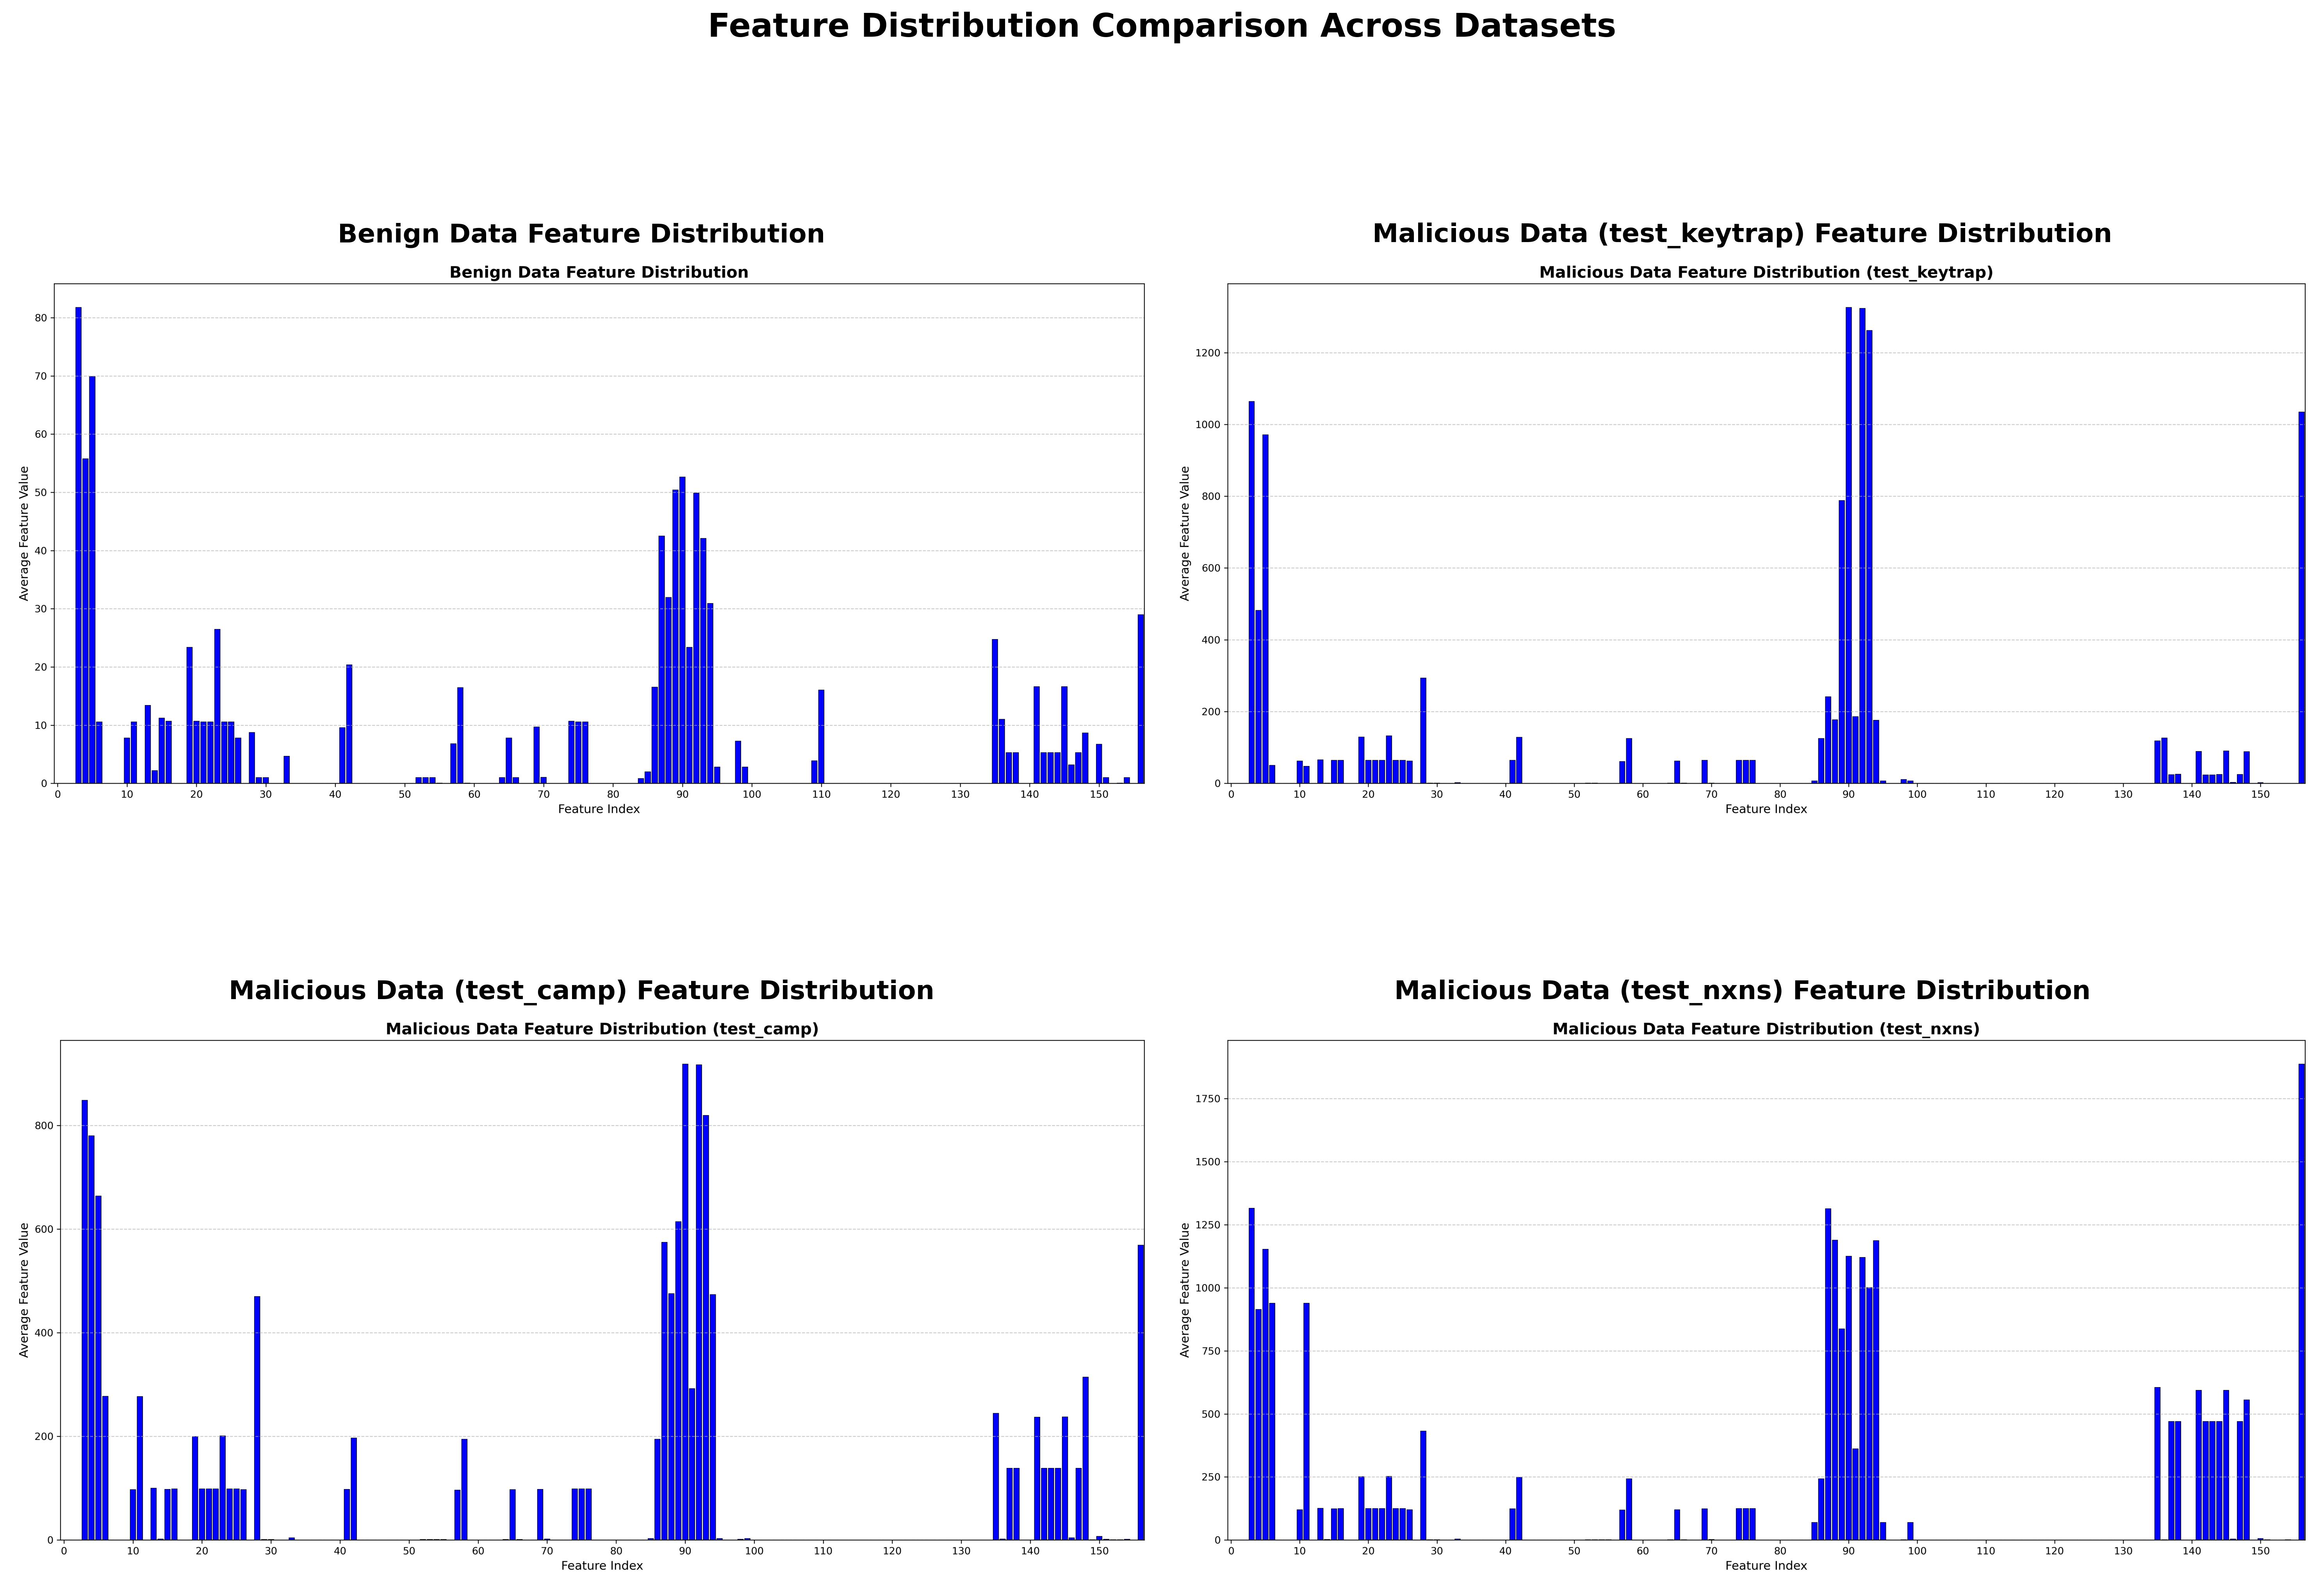

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import matplotlib.image as mpimg

def plot_single_feature_distribution(data_path, output_path, is_benign=False):
    """
    生成单个数据集的特征分布图，所有柱状图使用蓝色
    
    参数:
        data_path (str): 数据路径
        output_path (str): 输出图片路径
        is_benign (bool): 是否为良性数据
    """
    # 1. 加载数据并提取特征
    df = pd.read_csv(data_path)
    # 提取特征列（第4列开始）
    feature_cols = df.columns[3:]
    X = df[feature_cols].values
    
    input_dim = X.shape[1]
    print(f"Number of features: {input_dim} for {os.path.basename(data_path)}")
    
    # 2. 计算每个特征的平均值
    feature_means = np.mean(X, axis=0)
    
    # 3. 创建图表
    plt.figure(figsize=(16, 8))
    
    # 4. 绘制柱状图（全部使用蓝色）
    plt.bar(range(input_dim), feature_means, color='blue', edgecolor='black', linewidth=0.5)
    
    # 5. 添加图表元素
    dataset_name = os.path.basename(os.path.dirname(data_path))
    
    if is_benign:
        plt.title('Benign Data Feature Distribution', fontsize=16, fontweight='bold')
    else:
        plt.title(f'Malicious Data Feature Distribution ({dataset_name})', fontsize=16, fontweight='bold')
    
    plt.xlabel('Feature Index', fontsize=12)
    plt.ylabel('Average Feature Value', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # 6. 设置横坐标
    # 每10个特征显示一个刻度，最多显示15个刻度
    step = max(1, input_dim // 15)
    plt.xticks(range(0, input_dim, step))
    plt.xlim(-0.5, input_dim-0.5)
    
    # 7. 优化布局
    plt.tight_layout()
    
    # 8. 保存高分辨率图像
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Feature distribution chart saved to: {output_path}")
    
    # 9. 关闭图表（避免内存泄漏，特别是在生成多个图表时）
    plt.close()

def display_all_charts():
    """展示所有生成的特征分布图表"""
    # 图片路径列表
    chart_paths = [
        'benign_feature_distribution.png',
        'malicious_test_keytrap_feature_distribution.png',
        'malicious_test_camp_feature_distribution.png',
        'malicious_test_nxns_feature_distribution.png'
    ]
    
    # 检查图片是否存在
    existing_paths = [path for path in chart_paths if os.path.exists(path)]
    
    if not existing_paths:
        print("No charts found to display. Please generate the charts first.")
        return
    
    # 创建适当大小的子图布局 (2x2)
    n = len(existing_paths)
    rows = 2
    cols = 2
    
    plt.figure(figsize=(20, 16))
    
    for i, path in enumerate(existing_paths):
        # 读取图片
        img = mpimg.imread(path)
        
        # 创建子图
        ax = plt.subplot(rows, cols, i+1)
        plt.imshow(img)
        plt.axis('off')
        
        # 从文件名提取标题
        if i == 0:
            title = "Benign Data Feature Distribution"
        else:
            # 提取数据集名称（例如：test_keytrap）
            dataset_name = path.split('_')[1] + '_' + path.split('_')[2]
            title = f"Malicious Data ({dataset_name}) Feature Distribution"
        
        ax.set_title(title, fontsize=16, fontweight='bold', pad=10)
    
    # 添加全局标题
    plt.suptitle('Feature Distribution Comparison Across Datasets', 
                 fontsize=20, fontweight='bold', y=0.95)
    
    # 调整布局
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # 为全局标题留出空间
    
    # 保存汇总图
    summary_path = 'all_feature_distributions_summary.png'
    plt.savefig(summary_path, dpi=300, bbox_inches='tight')
    print(f"\nSummary chart of all distributions saved to: {summary_path}")
    
    # 显示图表
    plt.show()

# 在您的主程序中添加调用
if __name__ == "__main__":
    y = "binary"
    z = "157"
    
    # 使用test_keytrap目录下的良性数据（假设所有目录下的良性数据相同）
    BENIGN_PATH = f'preprocess/dataset_fanhua/{y}/{z}/test_keytrap/Benign_data.csv'
    
    # 生成良性数据的特征分布图
    plot_single_feature_distribution(
        data_path=BENIGN_PATH,
        output_path='benign_feature_distribution.png',
        is_benign=True
    )
    
    # 三个恶意测试数据
    malicious_datasets = ['test_keytrap', 'test_camp', 'test_nxns']
    
    for dataset in malicious_datasets:
        MAL_TEST_PATH = f'preprocess/dataset_fanhua/{y}/{z}/{dataset}/merged_filtered_data_test.csv'
        
        # 生成恶意数据的特征分布图
        plot_single_feature_distribution(
            data_path=MAL_TEST_PATH,
            output_path=f'malicious_{dataset}_feature_distribution.png',
            is_benign=False
        )
    
    print("\nSuccessfully generated 4 feature distribution charts:")
    print("1. benign_feature_distribution.png")
    print("2. malicious_test_keytrap_feature_distribution.png")
    print("3. malicious_test_camp_feature_distribution.png")
    print("4. malicious_test_nxns_feature_distribution.png")
    
    # 新增：展示所有生成的图片
    print("\nDisplaying all generated charts in a single summary figure...")
    display_all_charts()



Global maximum feature value across all datasets: 0.1223
Number of features: 107 for Benign_data.csv
Feature distribution chart saved to: benign_feature_distribution.png
Number of features: 107 for merged_filtered_data_test.csv
Feature distribution chart saved to: malicious_test_keytrap_feature_distribution.png
Number of features: 107 for merged_filtered_data_test.csv
Feature distribution chart saved to: malicious_test_camp_feature_distribution.png
Number of features: 107 for merged_filtered_data_test.csv
Feature distribution chart saved to: malicious_test_nxns_feature_distribution.png

Successfully generated 4 feature distribution charts with the same Y-axis scale:
1. benign_feature_distribution.png
2. malicious_test_keytrap_feature_distribution.png
3. malicious_test_camp_feature_distribution.png
4. malicious_test_nxns_feature_distribution.png

Displaying all generated charts in a single summary figure with consistent Y-axis...

Summary chart of all distributions saved to: all_featur

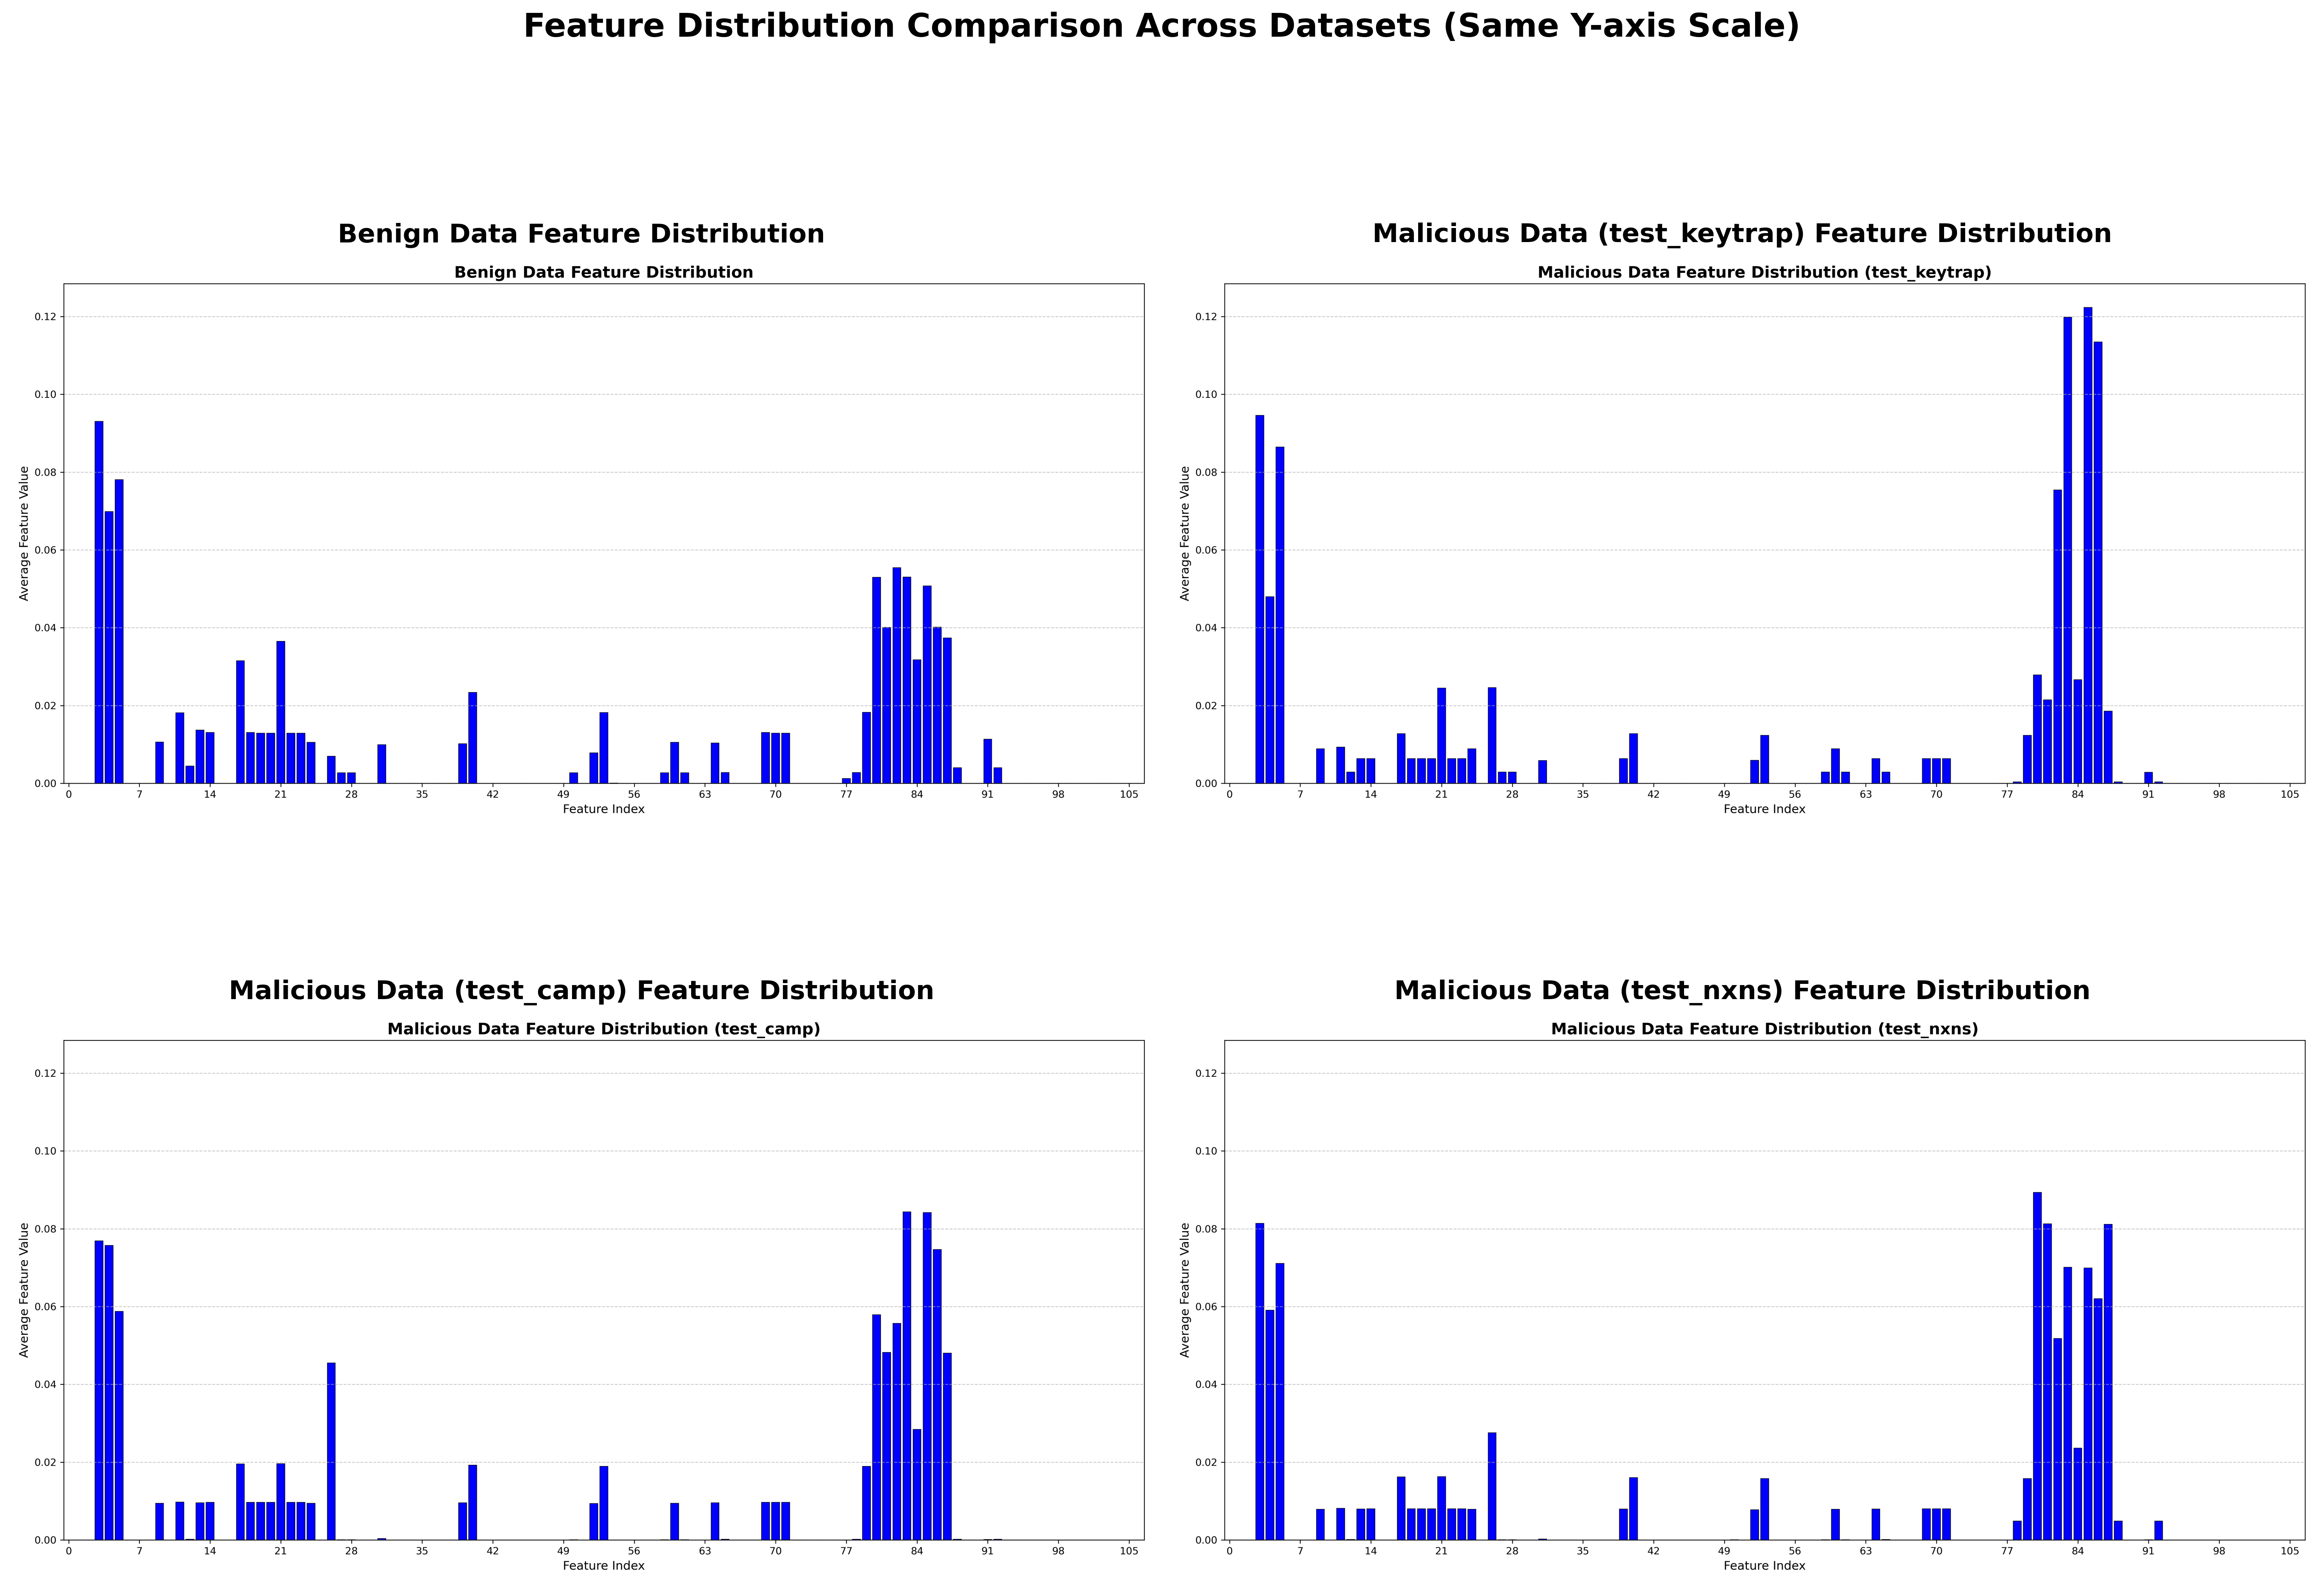

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import matplotlib.image as mpimg

def get_feature_means(data_path):
    """获取数据集中各特征的平均值"""
    df = pd.read_csv(data_path)
    # 提取特征列（第4列开始）
    feature_cols = df.columns[3:]
    X = df[feature_cols].values
    
    # 计算每个特征的平均值
    return np.mean(X, axis=0)

def plot_single_feature_distribution(data_path, output_path, y_max, is_benign=False):
    """
    生成单个数据集的特征分布图，所有柱状图使用蓝色，使用统一的纵坐标范围
    
    参数:
        data_path (str): 数据路径
        output_path (str): 输出图片路径
        y_max (float): 统一的纵坐标最大值
        is_benign (bool): 是否为良性数据
    """
    # 1. 加载数据并提取特征
    df = pd.read_csv(data_path)
    # 提取特征列（第4列开始）
    feature_cols = df.columns[3:]
    X = df[feature_cols].values
    
    input_dim = X.shape[1]
    print(f"Number of features: {input_dim} for {os.path.basename(data_path)}")
    
    # 2. 计算每个特征的平均值
    feature_means = np.mean(X, axis=0)
    
    # 3. 创建图表
    plt.figure(figsize=(16, 8))
    
    # 4. 绘制柱状图（全部使用蓝色）
    plt.bar(range(input_dim), feature_means, color='blue', edgecolor='black', linewidth=0.5)
    
    # 5. 添加图表元素
    dataset_name = os.path.basename(os.path.dirname(data_path))
    
    if is_benign:
        plt.title('Benign Data Feature Distribution', fontsize=16, fontweight='bold')
    else:
        plt.title(f'Malicious Data Feature Distribution ({dataset_name})', fontsize=16, fontweight='bold')
    
    plt.xlabel('Feature Index', fontsize=12)
    plt.ylabel('Average Feature Value', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    # 6. 设置坐标轴范围（使用统一的y_max）
    plt.ylim(0, y_max * 1.05)  # 留出5%的顶部空间
    # 设置横坐标
    step = max(1, input_dim // 15)
    plt.xticks(range(0, input_dim, step))
    plt.xlim(-0.5, input_dim-0.5)
    
    # 7. 优化布局
    plt.tight_layout()
    
    # 8. 保存高分辨率图像
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Feature distribution chart saved to: {output_path}")
    
    # 9. 关闭图表
    plt.close()

def display_all_charts():
    """展示所有生成的特征分布图表，使用相同的纵坐标范围"""
    # 图片路径列表
    chart_paths = [
        'benign_feature_distribution.png',
        'malicious_test_keytrap_feature_distribution.png',
        'malicious_test_camp_feature_distribution.png',
        'malicious_test_nxns_feature_distribution.png'
    ]
    
    # 检查图片是否存在
    existing_paths = [path for path in chart_paths if os.path.exists(path)]
    
    if not existing_paths:
        print("No charts found to display. Please generate the charts first.")
        return
    
    # 创建适当大小的子图布局 (2x2)
    n = len(existing_paths)
    rows = 2
    cols = 2
    
    plt.figure(figsize=(20, 16))
    
    for i, path in enumerate(existing_paths):
        # 读取图片
        img = mpimg.imread(path)
        
        # 创建子图
        ax = plt.subplot(rows, cols, i+1)
        plt.imshow(img)
        plt.axis('off')
        
        # 从文件名提取标题
        if i == 0:
            title = "Benign Data Feature Distribution"
        else:
            # 提取数据集名称
            dataset_name = path.split('_')[1] + '_' + path.split('_')[2]
            title = f"Malicious Data ({dataset_name}) Feature Distribution"
        
        ax.set_title(title, fontsize=16, fontweight='bold', pad=10)
    
    # 添加全局标题
    plt.suptitle('Feature Distribution Comparison Across Datasets (Same Y-axis Scale)', 
                 fontsize=20, fontweight='bold', y=0.95)
    
    # 调整布局
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # 为全局标题留出空间
    
    # 保存汇总图
    summary_path = 'all_feature_distributions_summary.png'
    plt.savefig(summary_path, dpi=300, bbox_inches='tight')
    print(f"\nSummary chart of all distributions saved to: {summary_path}")
    
    # 显示图表
    plt.show()

# 在您的主程序中添加调用
if __name__ == "__main__":
    y = "normalization"
    z = "107"
    
    # 使用test_keytrap目录下的良性数据（假设所有目录下的良性数据相同）
    BENIGN_PATH = f'preprocess/dataset_fanhua/{y}/{z}/test_keytrap/Benign_data.csv'
    
    # 三个恶意测试数据
    malicious_datasets = ['test_keytrap', 'test_camp', 'test_nxns']
    MAL_TEST_PATHS = [
        f'preprocess/dataset_fanhua/{y}/{z}/test_keytrap/merged_filtered_data_test.csv',
        f'preprocess/dataset_fanhua/{y}/{z}/test_camp/merged_filtered_data_test.csv',
        f'preprocess/dataset_fanhua/{y}/{z}/test_nxns/merged_filtered_data_test.csv'
    ]
    
    # 1. 计算所有数据集中特征平均值的最大值
    all_means = []
    
    # 添加良性数据
    all_means.append(get_feature_means(BENIGN_PATH))
    
    # 添加所有恶意数据
    for path in MAL_TEST_PATHS:
        all_means.append(get_feature_means(path))
    
    # 找出所有平均值中的最大值
    global_max = np.max(np.concatenate(all_means))
    print(f"\nGlobal maximum feature value across all datasets: {global_max:.4f}")
    
    # 2. 生成良性数据的特征分布图（使用统一的y轴范围）
    plot_single_feature_distribution(
        data_path=BENIGN_PATH,
        output_path='benign_feature_distribution.png',
        y_max=global_max,
        is_benign=True
    )
    
    # 3. 生成恶意数据的特征分布图
    for i, dataset in enumerate(malicious_datasets):
        MAL_TEST_PATH = MAL_TEST_PATHS[i]
        
        # 生成恶意数据的特征分布图（使用统一的y轴范围）
        plot_single_feature_distribution(
            data_path=MAL_TEST_PATH,
            output_path=f'malicious_{dataset}_feature_distribution.png',
            y_max=global_max,
            is_benign=False
        )
    
    print("\nSuccessfully generated 4 feature distribution charts with the same Y-axis scale:")
    print("1. benign_feature_distribution.png")
    print("2. malicious_test_keytrap_feature_distribution.png")
    print("3. malicious_test_camp_feature_distribution.png")
    print("4. malicious_test_nxns_feature_distribution.png")
    
    # 4. 展示所有生成的图片
    print("\nDisplaying all generated charts in a single summary figure with consistent Y-axis...")
    display_all_charts()
